# 01 – Umgebung und Rohdaten prüfen und verstehen

**Ziel.** Bevor gerechnet wird, prüfen wir sechs Dinge:
1. Läuft die Umgebung mit den festgelegten Versionen? (Abschnitte 1–2)
2. Sind alle Rohdaten vollständig? (Abschnitt 3)
3. Was steht in den Daten? (Abschnitte 4–9) – in der ML-Pipeline heisst das *Dateninspektion* und *explorative Analyse*.
4. Was zeigt das Luftbild – und wo sind Parkfelder schwer zu sehen? (Abschnitte 10–12)
5. Was ist bei den Feldern zu sehen, deren Datum nach der Befliegung liegt? (Abschnitt 13)
6. Auf welchen Grundstücken liegen die DAV-Felder? (Abschnitt 14)

Abschnitt 15 fasst die Beobachtungen zusammen und sammelt die offenen Fragen. Beantwortet werden sie im nächsten Notebook, `01b_methodik_leitfaden`.

**Warum.** Eine wissenschaftliche Arbeit muss reproduzierbar sein. Und erst wer die Daten kennt, kann eine passende Methodik wählen. Dieses Notebook **schaut nur hin**; Entscheidungen über die Methodik werden daraus abgeleitet und erst im folgenden Notebook (`01b`) getroffen.

**Nebenbei speichern wir die DAV-Daten** in einer einfacheren Form (ein Punkt je Zeile), damit man sie leichter weiterverwenden kann. Inhaltlich wird nichts verändert.

**Eingaben:** `daten/roh/`, Gebiet und Vermessung aus Notebook 00. **Ausgaben:** `daten/verarbeitet/dav_punkte.gpkg`, `daten/verarbeitet/dav_linien.gpkg`, Abbildungen in `ergebnisse/abbildungen/`.

In [1]:
import json                        # Einstellungen lesen und speichern
from pathlib import Path           # Pfade zusammensetzen

ROOT = Path.cwd().parent                             # Projektordner (eine Ebene über notebooks/)
ROH = ROOT / "daten" / "roh"                         # Rohdaten (werden nie verändert)
VERARB = ROOT / "daten" / "verarbeitet"              # abgeleitete Daten
ABB = ROOT / "ergebnisse" / "abbildungen"            # Abbildungen
ORTHO_DIR = ROH / "orthofoto" / "sommer_2024_25"     # Luftbild-Kacheln
ABB.mkdir(parents=True, exist_ok=True)               # Ordner anlegen, falls er fehlt

# Einstellungen aus Notebook 00 lesen (json.loads macht aus dem Text der Datei ein Wörterbuch)
EINST = json.loads((ROOT / "einstellungen.json").read_text(encoding="utf-8"))
CRS = EINST["CRS"]                                   # Koordinatensystem LV95
GEBIET_NAME = EINST["GEBIET_NAME"]                   # z. B. "kreis1"
print("Einstellungen aus Notebook 00: CRS =", CRS, "| Gebiet =", GEBIET_NAME)

import hashlib                     # Fingerabdruck (SHA-256) einer Datei
import warnings                    # harmlose Hinweise von Hilfspaketen ausblenden
warnings.filterwarnings("ignore", message="IProgress not found")
import pandas as pd                # Tabellen
import geopandas as gpd            # Tabellen mit Geometrie (Punkte, Linien, Flächen)
import rasterio                    # Luftbilder (GeoTIFF) lesen
import matplotlib.pyplot as plt    # Abbildungen
from matplotlib_inline.backend_inline import set_matplotlib_formats   # Format der Bilder im Notebook wählen
set_matplotlib_formats("jpeg", pil_kwargs={"quality": 85})   # Bilder im Notebook als JPEG einbetten: Luftbilder brauchen so rund zehnmal weniger Platz. Die Dateien in ergebnisse/abbildungen bleiben PNG

Einstellungen aus Notebook 00: CRS = EPSG:2056 | Gebiet = kreis1


## 1. Versionen der wichtigsten Pakete

Ein **Paket** ist fertiger Code, den andere geschrieben haben. Andere Versionen können andere Zahlen liefern; darum halten wir fest, mit welchen gerechnet wurde. Die vollständige Liste steht in `requirements-lock.txt`.

In [2]:
import platform, numpy, shapely, pyproj, torch, torchvision, mlflow     # nur, um die Versionen abzufragen
# Jedes Paket kennt seine Version unter dem Namen __version__
pakete = [
    ("Python", platform.python_version(), "Programmiersprache"),
    ("numpy", numpy.__version__, "Rechnen mit Zahlenblöcken – ein Bild ist ein Zahlenblock"),
    ("pandas", pd.__version__, "Tabellen"),
    ("geopandas", gpd.__version__, "Tabellen mit Geometrie (Punkte, Linien, Flächen)"),
    ("shapely", shapely.__version__, "Geometrie-Rechnungen (liegt in, Schnitt, Puffer)"),
    ("pyproj", pyproj.__version__, "Koordinatensysteme umrechnen"),
    ("rasterio", rasterio.__version__, "Luftbilder mit Lage lesen"),
    ("torch", torch.__version__, "neuronale Netze (Deep Learning)"),
    ("torchvision", torchvision.__version__, "vortrainierte Bildmodelle (DenseNet-121)"),
    ("mlflow", mlflow.__version__, "Trainingsläufe protokollieren"),
]
pd.DataFrame(pakete, columns=["Paket", "Version", "wofür"])       # Liste -> Tabelle zum Anzeigen

,Paket,Version,wofür
0,Python,3.11.9,Programmiersprache
1,numpy,2.4.6,Rechnen mit Zahlenblöcken – ein Bild ist ein Z...
2,pandas,3.1.1,Tabellen
3,geopandas,1.2.0,"Tabellen mit Geometrie (Punkte, Linien, Flächen)"
4,shapely,2.2.0,"Geometrie-Rechnungen (liegt in, Schnitt, Puffer)"
5,pyproj,3.7.2,Koordinatensysteme umrechnen
6,rasterio,1.4.4,Luftbilder mit Lage lesen
7,torch,2.11.0+cu128,neuronale Netze (Deep Learning)
8,torchvision,0.26.0+cu128,vortrainierte Bildmodelle (DenseNet-121)
9,mlflow,3.18.0,Trainingsläufe protokollieren


## 2. Grafikkarte

Das Training braucht eine NVIDIA-Grafikkarte (CUDA = die Schnittstelle zur Grafikkarte). Entscheidend ist der **freie** Speicher; der Bildschirm belegt einen Teil.

In [3]:
if torch.cuda.is_available():                                      # gibt es eine nutzbare Grafikkarte?
    frei, gesamt = torch.cuda.mem_get_info()                       # freier und gesamter Speicher in Byte
    print(torch.cuda.get_device_name(0), f"| frei {frei / 1e9:.1f} GB von {gesamt / 1e9:.1f} GB")   # Byte / 1e9 = GB
else:
    print("Keine CUDA-Grafikkarte gefunden: Training wäre nur auf dem Prozessor möglich (sehr langsam).")

NVIDIA GeForce RTX 4070 Ti | frei 11.6 GB von 12.9 GB


## 3. Sind alle Rohdaten vollständig?

Das **Manifest** (`daten/roh/MANIFEST.csv`) wurde beim Herunterladen geschrieben: eine Zeile je Datei, mit ihrer Grösse in Byte. Wir prüfen für jede Datei:
1. Ist sie da?
2. Hat sie noch dieselbe Grösse wie beim Download? Wenn ja, ist sie mit hoher Wahrscheinlichkeit vollständig.

*Für Genauigkeit:* Mit dem Schalter `FINGERABDRUCK_PRUEFEN = True` wird zusätzlich der Fingerabdruck (SHA-256) verglichen. Er beweist, dass sich kein einziges Byte verändert hat, dauert bei 8 GB aber einige Minuten.

In [4]:
manifest = pd.read_csv(ROH / "MANIFEST.csv")                       # VORHER: alle Einträge
print("Einträge im Manifest:", len(manifest))
manifest = manifest[manifest.datei.str.startswith("daten/roh/")]   # nur Rohdaten (Literatur-PDFs ausblenden)
print("davon Rohdaten:", len(manifest))
manifest[["datei", "bytes"]].head(3)                               # so sehen die Einträge aus

Einträge im Manifest: 72
davon Rohdaten: 61


,datei,bytes
0,daten/roh/grenzen/adm_stadtkreise_a.geojson,645097
1,daten/roh/liegenschaften/v_lvz_grundstueck.geo...,10003820
2,daten/roh/modelle/torch/hub/checkpoints/densen...,32342954


In [5]:
FINGERABDRUCK_PRUEFEN = False      # True: zusätzlich SHA-256 vergleichen (einige Minuten)

def pruefe(zeile):
    # Prüft EINE Zeile des Manifests und gibt einen kurzen Text zurück
    pfad = ROOT / zeile.datei                              # Projektordner + Pfad aus dem Manifest
    if not pfad.exists():                                  # 1. Ist die Datei da?
        return "FEHLT"
    if pfad.stat().st_size != zeile.bytes:                 # 2. Gleiche Grösse in Byte?
        return "GRÖSSE FALSCH"
    if FINGERABDRUCK_PRUEFEN:                              # optional: gleicher Fingerabdruck?
        with pfad.open("rb") as f:
            if hashlib.file_digest(f, "sha256").hexdigest() != zeile.sha256:
                return "FINGERABDRUCK FALSCH"
    return "ok"

# itertuples() geht die Tabelle Zeile für Zeile durch; für jede Zeile wird pruefe aufgerufen
manifest["status"] = [pruefe(zeile) for zeile in manifest.itertuples()]
print(manifest.status.value_counts().to_string())                  # wie oft kommt jeder Status vor?

status
ok    61


## 4. Das Gebiet

Notebook 00 hat das Gebiet bestimmt und als Datei gespeichert. Wir lesen es: zuerst als Tabelle, dann nehmen wir die Fläche selbst heraus (wie in Notebook 00 erklärt).

In [6]:
gebiet_tabelle = gpd.read_file(VERARB / "gebiet.geojson")          # Tabelle mit 1 Zeile
gebiet = gebiet_tabelle.geometry.iloc[0]                           # Spalte "geometry", erste Zeile -> die Fläche selbst
print(type(gebiet_tabelle).__name__, "→", type(gebiet).__name__, "|", round(gebiet.area / 1_000_000, 2), "km²")

GeoDataFrame → Polygon | 1.8 km²


## 5. Die Kürzel der DAV

Wir arbeiten mit den **Original-Kürzeln der DAV** (Entscheid Auftraggeber). Zwei Spalten sind für uns wichtig:

| Spalte | Wert | Bedeutung |
| --- | --- | --- |
| `orientierung` (Parkart) | `LPU` | Längsparkierung: Autos stehen hintereinander, parallel zur Strasse |
| | `QPU` | Querparkierung: Autos stehen nebeneinander, quer zur Strasse |
| | `SCHPU` | Schrägparkierung: Autos stehen schräg zur Strasse |
| `art` (Nutzung) | `Standard` | weiss markiert, gebührenpflichtig (Parkuhr), meist 2 Stunden |
| | `Blaue Zone`, `Parkscheibe` | blau markiert bzw. mit Parkscheibe, gratis mit Zeitlimit |
| | `Güterumschlag`, `Taxi`, `Güter / Taxi`, `Car`, `Polizei`, `Invalid`, `Elektro`, `Diverse` | reserviert, mit eigener Markierung (z. B. gelb/orange, grün für Elektro) |

Die Kürzel bleiben unverändert so, wie die DAV sie liefert.

## 6. DAV-Parkfelder aufbereiten

Jede Zeile soll am Schluss **ein Parkfeld** sein, gespeichert als Punkt in der Mitte des Feldes. Die Daten umfassen die ganze Stadt. Drei Schritte:

**Schritt 1 – Lesen.** Die Rohdatei wird gelesen und in Schweizer Koordinaten gebracht (`to_crs`).

In [7]:
roh = gpd.read_file(ROH / "parkplaetze/DAV_oeff_strassenparkierung_dav_p.geojson").to_crs(CRS)
print("Rohdatei:", len(roh), "Zeilen,", roh.shape[1], "Spalten")
print("Arten von Geometrie:", roh.geom_type.value_counts().to_dict())   # Punkt oder Mehrfachpunkt?
roh[["bezeichnung", "art", "orientierung", "geometry"]].head(3)

Rohdatei: 13104 Zeilen, 18 Spalten
Arten von Geometrie: {'MultiPoint': 13104}


,bezeichnung,art,orientierung,geometry
0,Kappelergasse Nr. 1,Standard,SCHPU,MULTIPOINT ((2683305.986 1247054.163))
1,Kappelergasse Nr. 1,Standard,SCHPU,MULTIPOINT ((2683300.658 1247053.148))
2,Kappelergasse Nr. 1,Standard,SCHPU,MULTIPOINT ((2683303.322 1247053.655))


**Schritt 2 – Zerlegen: von *MultiPoint* zu *Point*.** Die Stadt speichert jedes Feld als *MultiPoint* (Mehrfachpunkt) – einen **Behälter**, der mehrere Punkte aufnehmen könnte. `explode` packt jeden Punkt aus und macht daraus eine eigene Zeile mit einem einfachen *Point*.

Warum nicht beim *MultiPoint* bleiben?
- **Eine Zeile = ein Parkfeld** muss sicher gelten. Enthielte ein Behälter einmal zwei Punkte, würden wir zwei Felder als eines zählen.
- **Koordinaten:** Nur ein einfacher *Point* hat direkt eine x- und y-Koordinate (`.x`, `.y`). Beim Behälter müsste man jedes Mal erst den Punkt herausnehmen.

Hier enthält jeder Behälter genau einen Punkt: Die Anzahl bleibt gleich, nur die Art der Geometrie wird einfacher. `reset_index` nummeriert die Zeilen danach neu (0, 1, 2, …).

In [8]:
dav = roh.explode(index_parts=False).reset_index(drop=True)
print(f"Vorher: {len(roh)} Zeilen, Geometrie {roh.geom_type.unique().tolist()}")
print(f"Nachher: {len(dav)} Zeilen (= Parkfelder), Geometrie {dav.geom_type.unique().tolist()}")
print("Erster Punkt vorher:", roh.geometry.iloc[0], "→ nachher:", dav.geometry.iloc[0])

Vorher: 13104 Zeilen, Geometrie ['MultiPoint']
Nachher: 13104 Zeilen (= Parkfelder), Geometrie ['Point']
Erster Punkt vorher: MULTIPOINT ((2683305.985683 1247054.162505)) → nachher: POINT (2683305.985683 1247054.162505)


**Schritt 3 – Speichern** (ganze Stadt). Die Spalte `geometrie_gdo` ist in den DAV-Daten immer leer und wird weggelassen.

In [9]:
dav.drop(columns=["geometrie_gdo"], errors="ignore").to_file(VERARB / "dav_punkte.gpkg", driver="GPKG")
print("gespeichert: daten/verarbeitet/dav_punkte.gpkg mit", len(dav), "Parkfeldern")

gespeichert: daten/verarbeitet/dav_punkte.gpkg mit 13104 Parkfeldern


## 7. Die Parkfelder im Gebiet ansehen

**Auswahl** wie in Notebook 00: `dav.within(gebiet)` fragt jeden Punkt "liegst du im Gebiet?" und liefert eine Spalte aus True/False (Maske); `dav[maske]` behält nur die Zeilen mit True.

In [10]:
maske = dav.within(gebiet)                                         # True/False je Parkfeld
dav_gebiet = dav[maske]                                            # nur die Parkfelder im Gebiet
print(f"Vorher (Stadt): {len(dav)} Parkfelder → nachher (Gebiet): {len(dav_gebiet)}")

Vorher (Stadt): 13104 Parkfelder → nachher (Gebiet): 1252


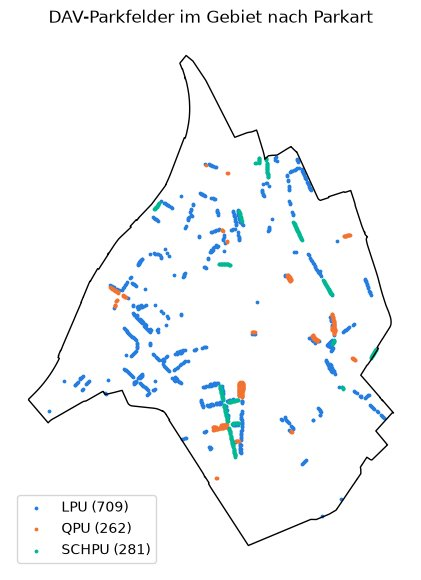

In [11]:
# Karte: das Gebiet und die Parkfelder, gefärbt nach Parkart
fig, ax = plt.subplots(figsize=(6, 7))                             # leeres Blatt mit einer Zeichenfläche
gebiet_tabelle.boundary.plot(ax=ax, color="black", lw=1)           # Ebene 1: Umriss des Gebiets
farben = {"LPU": "#257de0", "QPU": "#f47230", "SCHPU": "#00b894"}   # Projektfarben je Parkart
for code, farbe in farben.items():                                 # für jede Parkart eine Ebene:
    teil = dav_gebiet[dav_gebiet.orientierung == code]             #   nur die Felder dieser Parkart (Maske)
    teil.plot(ax=ax, color=farbe, markersize=3, label=f"{code} ({len(teil)})")   # Punkte; label = Text für die Legende
ax.legend(loc="lower left")                                        # Legende aus allen labels
ax.set_title("DAV-Parkfelder im Gebiet nach Parkart")
ax.set_axis_off()
fig.savefig(ABB / "01_dav_parkfelder.png", dpi=130, bbox_inches="tight")   # Bild speichern
plt.show()

**Datenqualität: Wo fehlen Werte?** Hier wird **nichts entfernt** – wir schauen nur hin, welche Angaben vollständig sind und welche Lücken haben.

`isna()` fragt jede Zelle "fehlt der Wert?" (True/False). `.sum()` zählt je Spalte die fehlenden Werte (True zählt als 1), `.mean()` gibt den Anteil. Dazu eine kurze Beschreibung, was in der Spalte steht.

In [12]:
uebersicht = pd.DataFrame({
    "fehlend": dav_gebiet.drop(columns="geometry").isna().sum(),                      # Anzahl je Spalte
    "anteil": dav_gebiet.drop(columns="geometry").isna().mean().round(3),             # Anteil je Spalte
})
inhalt = {"orientierung": "Parkart (LPU, QPU, SCHPU)", "art": "Art/Nutzung (Standard, Blaue Zone, Taxi …)",
          "bezeichnung": "Ort, meist Strassenname mit Nummer", "inbetriebnahme": "Datum der Inbetriebnahme",
          "parkdauer": "erlaubte Parkdauer in Minuten", "parkfeldnummer": "Nummer des Feldes",
          "gebpflicht": "gebührenpflichtig (1) oder nicht (0)", "geometrie_gdo": "(in den DAV-Daten immer leer)"}
uebersicht["inhalt"] = [inhalt.get(spalte, "") for spalte in uebersicht.index]
print(len(dav_gebiet), "Parkfelder im Gebiet; es wird keine Zeile entfernt.")
uebersicht

1252 Parkfelder im Gebiet; es wird keine Zeile entfernt.


,fehlend,anteil,inhalt
id,0,0.000,
art,0,0.000,"Art/Nutzung (Standard, Blaue Zone, Taxi …)"
bezeichnung,203,0.162,"Ort, meist Strassenname mit Nummer"
davnr,203,0.162,
dienstabteilung,0,0.000,
eigentum,0,0.000,
gebpflicht,0,0.000,gebührenpflichtig (1) oder nicht (0)
geometrie_gdo,1252,1.000,(in den DAV-Daten immer leer)
inbetriebnahme,0,0.000,Datum der Inbetriebnahme
inprojekt,0,0.000,


In [13]:
# Duplikate: Liegt ein Punkt doppelt an derselben Stelle? (wäre ein Feld, das zweimal gezählt würde)
print("Doppelte Punkte (gleiche Lage):", dav_gebiet.geometry.duplicated().sum())

Doppelte Punkte (gleiche Lage): 0


**Art der Felder.** `value_counts()` zählt, wie oft jeder Wert vorkommt – im Gebiet und zum Vergleich in der ganzen Stadt.

In [14]:
pd.DataFrame({"Gebiet": dav_gebiet.art.value_counts(), "Stadt": dav.art.value_counts()}).fillna(0).astype(int)

,Gebiet,Stadt
art,,
Blaue Zone,0,3117
Car,11,42
Diverse,0,6
Elektro,4,13
Güter / Taxi,4,6
Güterumschlag,42,379
Invalid,22,269
Parkscheibe,0,610
Polizei,23,60


**Zeitpunkt.** Das Luftbild stammt vom Sommer 2024/25. Das DAV-Feld `inbetriebnahme` zeigt, seit wann ein Feld erfasst ist. Liegt das Datum *nach* der Befliegung, ist das Feld im Luftbild vielleicht noch gar nicht zu sehen. Ob das Datum den Bau oder nur eine Neuerfassung bedeutet, ist ungeklärt.

`pd.to_datetime` macht aus dem Text (z. B. "2022-08-25") ein Datum; `.dt.year` nimmt davon das Jahr.

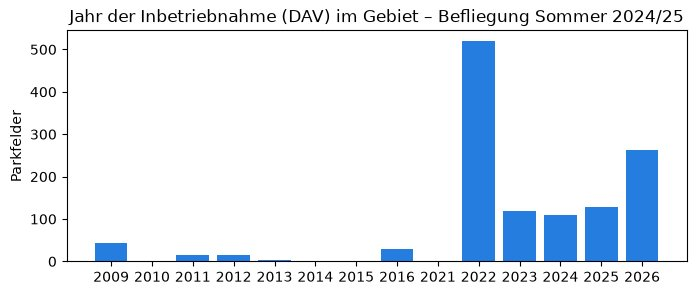

Nach dem 1.1.2025 in Betrieb genommen: 390 von 1252


In [15]:
datum = pd.to_datetime(dav_gebiet.inbetriebnahme, errors="coerce")     # Text -> Datum (unlesbare Werte -> leer)
anzahl_je_jahr = datum.dt.year.value_counts().sort_index()             # Anzahl Felder je Jahr, nach Jahr sortiert

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(anzahl_je_jahr.index.astype(int).astype(str), anzahl_je_jahr.values, color="#257de0")   # Balken: Jahr -> Anzahl
ax.set_ylabel("Parkfelder")
ax.set_title("Jahr der Inbetriebnahme (DAV) im Gebiet – Befliegung Sommer 2024/25")
fig.savefig(ABB / "01_inbetriebnahme.png", dpi=130, bbox_inches="tight")
plt.show()
print("Nach dem 1.1.2025 in Betrieb genommen:", int((datum >= "2025-01-01").sum()), "von", len(dav_gebiet))

## 8. DAV-Parkstreifen (Linien)

Parkstreifen ohne Einzelmarkierung (vor allem Blaue Zone): keine Punkte, sondern **Linien mit einer Länge**. Die Art steht hier in der Spalte `typ`. Wir speichern die Linien unverändert als eigene Datei.

In [16]:
linien = gpd.read_file(ROH / "parkplaetze/DAV_oeff_strassenparkierung_dav_l.geojson").to_crs(CRS)
linien.to_file(VERARB / "dav_linien.gpkg", driver="GPKG")            # als eigene Datei speichern

linien_gebiet = linien[linien.intersects(gebiet)]                   # Maske: berührt die Linie das Gebiet?
print(f"Vorher (Stadt): {len(linien)} Linien → nachher (Gebiet): {len(linien_gebiet)} Linien, "
      f"zusammen {linien_gebiet.length.sum():.0f} m lang")           # .length = Länge in Metern
linien_gebiet[["typ", "geometry"]].head(3)

Vorher (Stadt): 5922 Linien → nachher (Gebiet): 84 Linien, zusammen 1418 m lang

,typ,geometry
30,Güter / Taxi,"MULTILINESTRING ((2683397.517 1247448.193, 268..."
99,Güterumschlag,"MULTILINESTRING ((2683118.064 1247651.318, 268..."
137,Güterumschlag,"MULTILINESTRING ((2683198.964 1247668.572, 268..."


## 9. Amtliche Vermessung

In Notebook 00 auf Gebiet + 250 m zugeschnitten.
- **Bodenbedeckung:** jede Fläche hat eine Art (`art_txt`), z. B. Strasse, Trottoir, Gebäude.
- **Strassenstücke:** Linien in der Mitte der Strassen, aufgeteilt in einzelne Stücke.

`groupby("art_txt")` bildet je Art eine Gruppe; `.sum()` zählt die Flächen jeder Gruppe zusammen.

In [17]:
bo = gpd.read_file(VERARB / f"bodenbedeckung_{GEBIET_NAME}.gpkg")        # Bodenbedeckung (Notebook 00)
bo["ha"] = bo.area / 10_000                                              # Fläche je Zeile: m² / 10'000 = Hektaren
flaeche_je_art = bo.groupby("art_txt")["ha"].sum().sort_values(ascending=False)   # je Art summiert, grösste zuerst
print(len(bo), "Flächen. Die 8 häufigsten Arten (Hektaren in Gebiet + Rand):")
print(flaeche_je_art.head(8).round(1).to_string())

achsen = gpd.read_file(VERARB / f"strassenstuecke_{GEBIET_NAME}.gpkg")   # Strassenstücke (Notebook 00)
print("\n", len(achsen), "Strassenstücke in Gebiet + Rand")

6945 Flächen. Die 8 häufigsten Arten (Hektaren in Gebiet + Rand):
art_txt
Gebaeude.Verwaltung                                  65.6
befestigt.Strasse_Weg.Strasse                        52.8
Gewaesser.stehendes                                  49.4
befestigt.uebrige_befestigte.Hausumschwung           47.7
humusiert.Gartenanlage.Gartenanlage_Hausumschwung    42.7
befestigt.Trottoir                                   36.7
Gebaeude.Wohngebaeude                                32.3
Gewaesser.fliessendes                                26.1

 1162 Strassenstücke in Gebiet + Rand


## 10. Das Luftbild

- **Kachel:** eine Datei von 1 × 1 km.
- **Kanal:** eine "Farbschicht" des Bildes. Unsere Kacheln haben 4 Kanäle: Rot, Grün, Blau und nahes Infrarot.
- **Auflösung:** Seitenlänge eines Pixels am Boden, hier 5 cm. Eine Kachel hat also 1000 m ÷ 0,05 m = 20'000 Pixel Seitenlänge.

`rasterio.open` öffnet eine Bilddatei, **ohne** die Pixel zu laden – man liest nur die Beschreibung. `with … as bild:` sorgt dafür, dass die Datei danach automatisch wieder geschlossen wird.

In [18]:
zeilen = []                                                    # Sammelliste: eine Zeile je Kachel
for pfad in sorted(ORTHO_DIR.glob("*.tif")):                    # alle Bilddateien, alphabetisch (wie in Notebook 00)
    with rasterio.open(pfad) as bild:                          # Datei öffnen (nur Beschreibung)
        zeilen.append(dict(kachel=pfad.stem,
                           kanaele=bild.count,                 # Anzahl Farbschichten
                           aufloesung_m=bild.res[0],           # Pixelgrösse in Metern
                           breite_px=bild.width, hoehe_px=bild.height))   # Anzahl Pixel
pd.DataFrame(zeilen)

,kachel,kanaele,aufloesung_m,breite_px,hoehe_px
0,2682_1246,4,0.05,20000,20000
1,2682_1247,4,0.05,20000,20000
2,2682_1248,4,0.05,20000,20000
3,2683_1246,4,0.05,20000,20000
4,2683_1247,4,0.05,20000,20000
5,2683_1248,4,0.05,20000,20000
6,2684_1246,4,0.05,20000,20000
7,2684_1247,4,0.05,20000,20000
8,2684_1248,4,0.05,20000,20000


**Einen Ausschnitt lesen.** Ein Ausschnitt kann über mehrere Kacheln reichen. Die Funktion `lies_luftbild` setzt ihn aus allen Kacheln zusammen (`merge`).

- `rahmen` = (links, unten, rechts, oben) in Metern;
- `aufloesung_m` = 0.05 für 5 cm; mit 0.10 wird je 2 × 2 Pixel der Mittelwert gebildet – so entsteht das 10-cm-Bild;
- `kanaele` = welche Farbschichten (1–3 = Farbe, 4 = Infrarot).

In [19]:
from rasterio.merge import merge          # mehrere Kacheln zu einem Ausschnitt zusammensetzen
from rasterio.enums import Resampling      # wie Pixel beim Vergröbern zusammengefasst werden (hier: Mittelwert)

def lies_luftbild(rahmen, aufloesung_m=0.05, kanaele=(1, 2, 3)):
    kacheln = [rasterio.open(p) for p in sorted(ORTHO_DIR.glob("*.tif"))]     # alle Kacheln öffnen
    bild, lage = merge(kacheln, bounds=rahmen, res=aufloesung_m, indexes=list(kanaele), resampling=Resampling.average)
    for k in kacheln:                                                          # Dateien wieder schliessen
        k.close()
    return bild, lage                       # bild: Zahlenblock [Kanäle, Zeilen, Spalten]; lage: Pixel -> Koordinate

# Ein Parkfeld an einer Strasse mit Bäumen als Mittelpunkt: dort unterscheiden sich die Kanäle deutlich
mitte = dav_gebiet[dav_gebiet.bezeichnung.fillna("").str.contains("Hirschengraben")].geometry.iloc[0]
rahmen = (mitte.x - 20, mitte.y - 20, mitte.x + 20, mitte.y + 20)  # 40 × 40 m darum herum
rgb, _ = lies_luftbild(rahmen, 0.05, kanaele=(1, 2, 3))          # Farbe; "_" = Rückgabe, die wir hier nicht brauchen
nir, _ = lies_luftbild(rahmen, 0.05, kanaele=(4,))               # Infrarot
print("Farbbild:", rgb.shape, "= (Kanäle, Zeilen, Spalten);  40 m ÷ 0,05 m = 800 Pixel")

Farbbild: (3, 800, 800) = (Kanäle, Zeilen, Spalten);  40 m ÷ 0,05 m = 800 Pixel


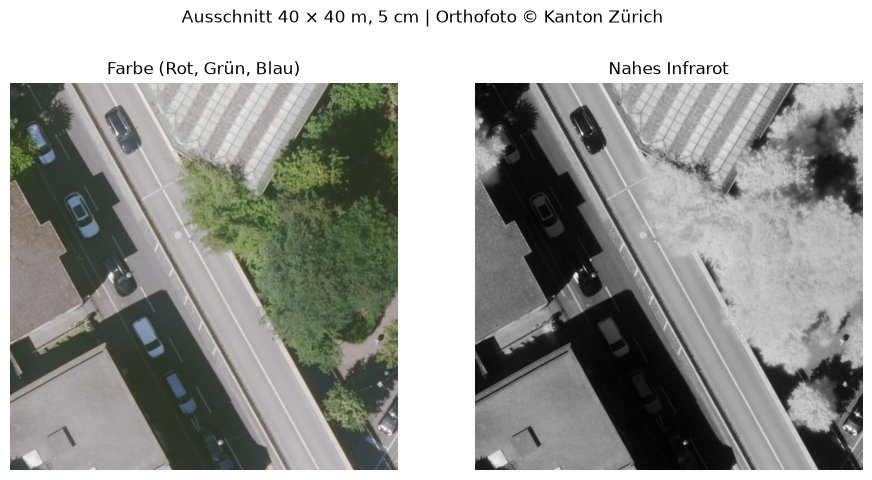

In [20]:
# Zwei Bilder nebeneinander: links Farbe, rechts Infrarot.
# Pflanzen strahlen Infrarot stark zurück und erscheinen hell – Bäume sind so leicht zu erkennen.
fig, axs = plt.subplots(1, 2, figsize=(11, 5.5))
axs[0].imshow(rgb.transpose(1, 2, 0))          # imshow zeigt ein Bild; es will [Zeilen, Spalten, Kanäle] -> umsortieren
axs[0].set_title("Farbe (Rot, Grün, Blau)")
axs[1].imshow(nir[0], cmap="gray")             # nir[0] = die einzige Schicht; cmap="gray" = Graustufen
axs[1].set_title("Nahes Infrarot")
for ax in axs:
    ax.set_axis_off()
fig.suptitle("Ausschnitt 40 × 40 m, 5 cm | Orthofoto © Kanton Zürich")
fig.savefig(ABB / "01_luftbild_kanaele.png", dpi=110, bbox_inches="tight")
plt.show()

**Die drei Farbkanäle einzeln.** Ein Farbbild besteht aus drei Schichten: Rot, Grün und Blau. Jede Schicht ist für sich **eine Zahl je Pixel** von 0 bis 255 – wie viel Licht *dieser Farbe* die Kamera dort gemessen hat (0 = nichts, 255 = sehr viel). Eine einzelne Schicht hat selbst keine Farbe; man zeigt sie darum als **Graubild** (oben) oder **in ihrer eigenen Farbe** (unten). Erst übereinandergelegt ergeben die drei Schichten das Farbbild.

So liest man die Bilder: Ein Gegenstand erscheint in dem Kanal **hell**, dessen Farbe er stark zurückwirft. Pflanzen sind im Grün-Kanal heller als im Rot- und Blau-Kanal; ein rotes Dach ist im Rot-Kanal hell. **Graue Flächen** (Strassen, viele Dächer) werfen alle Farben ähnlich stark zurück und sehen darum in allen drei Kanälen fast gleich aus – in einer Altstadt ist das ein grosser Teil des Bildes.

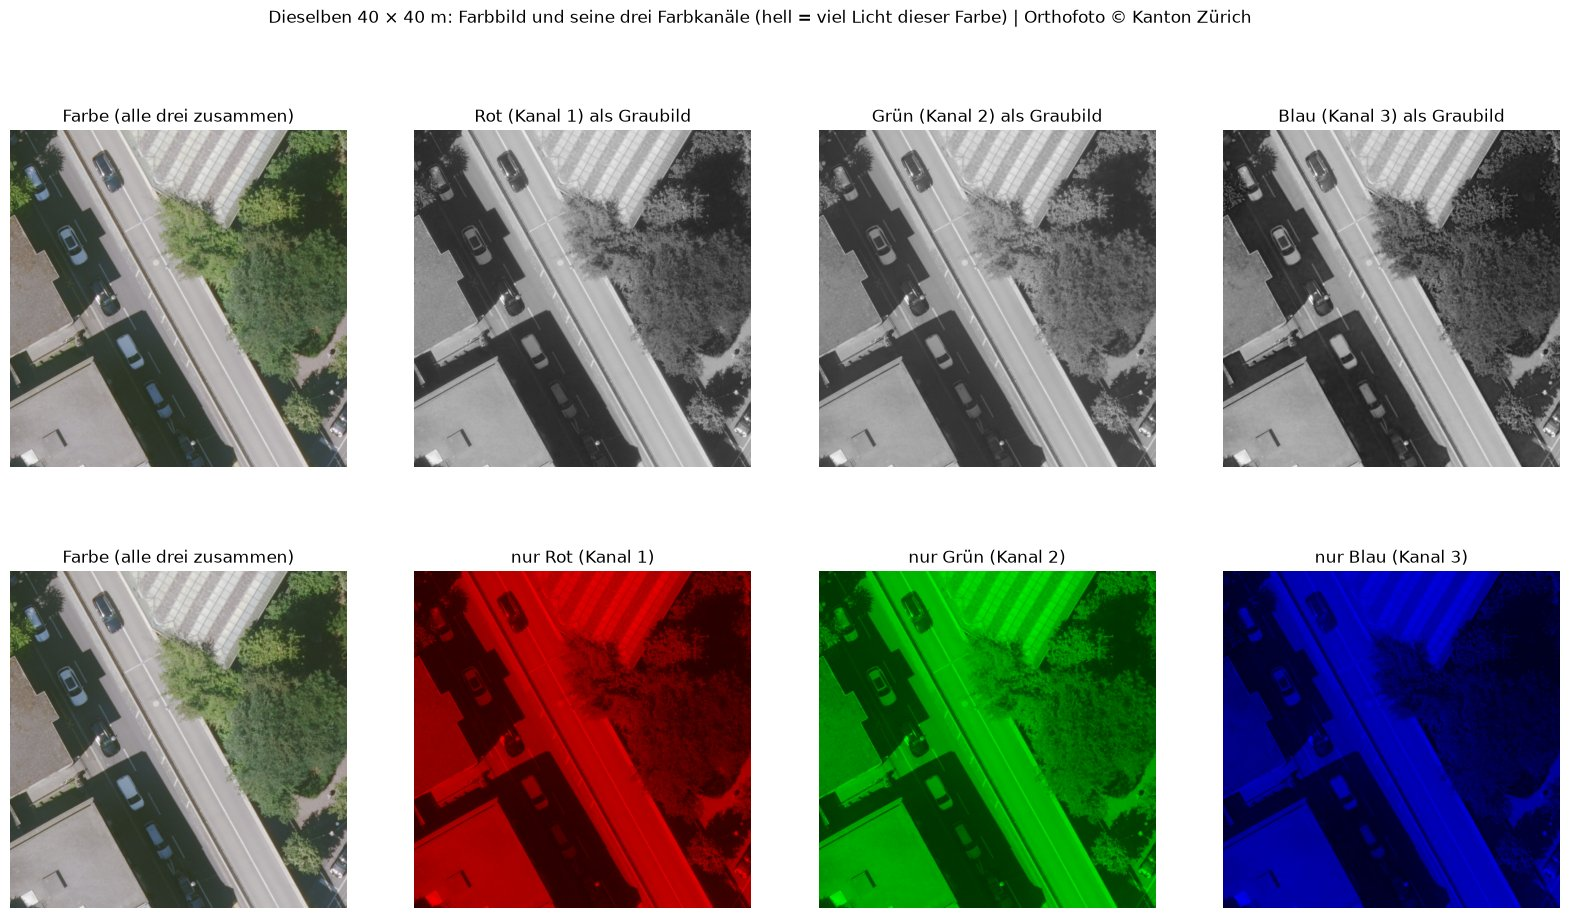

{'Rot (Kanal 1)': 119.6, 'Grün (Kanal 2)': 123.7, 'Blau (Kanal 3)': 112.2}


In [21]:
import numpy as np                                            # leere Schichten für die Farbdarstellung
namen = ["Rot (Kanal 1)", "Grün (Kanal 2)", "Blau (Kanal 3)"]
fig, axs = plt.subplots(2, 4, figsize=(20, 10.5))             # 2 Reihen × 4 Spalten

# Spalte 1: das Farbbild (alle drei Schichten zusammen), oben und unten gleich
for reihe in (0, 1):
    axs[reihe, 0].imshow(rgb.transpose(1, 2, 0))
    axs[reihe, 0].set_title("Farbe (alle drei zusammen)")

for i, name in enumerate(namen):                              # i = 0, 1, 2 -> Rot, Grün, Blau
    # Reihe 1: die Schicht als Graubild (0 = schwarz, 255 = weiss), für alle dieselbe Skala
    axs[0, i + 1].imshow(rgb[i], cmap="gray", vmin=0, vmax=255)
    axs[0, i + 1].set_title(f"{name} als Graubild")
    # Reihe 2: dieselbe Schicht in ihrer eigenen Farbe – die beiden anderen Schichten auf 0 gesetzt
    nur_diese = np.zeros_like(rgb)                            # drei leere Schichten (alles 0 = schwarz)
    nur_diese[i] = rgb[i]                                     # nur Schicht i übernehmen
    axs[1, i + 1].imshow(nur_diese.transpose(1, 2, 0))
    axs[1, i + 1].set_title(f"nur {name}")

for ax in axs.flat:
    ax.set_axis_off()
fig.suptitle("Dieselben 40 × 40 m: Farbbild und seine drei Farbkanäle (hell = viel Licht dieser Farbe) | Orthofoto © Kanton Zürich")
fig.savefig(ABB / "01_luftbild_rgb_einzeln.png", dpi=90, bbox_inches="tight")
plt.show()

# Mittlere Helligkeit je Kanal im Ausschnitt (0 = dunkel, 255 = hell)
print({name: round(float(rgb[i].mean()), 1) for i, name in enumerate(namen)})

**Kombinationen der Kanäle an einer Stelle mit vielen Parkfeldern.** Wie gut sind Parkfelder, Markierungen und Autos zu sehen, je nachdem, welche Kanäle man anschaut? Gezeigt wird ein Ausschnitt mit vielen Schrägparkfeldern:

| Bild | woraus | worauf achten |
| --- | --- | --- |
| Farbe | Rot, Grün, Blau | so sieht das Auge die Stelle |
| Falschfarben-Infrarot | Infrarot, Rot, Grün (statt Rot, Grün, Blau) | Pflanzen leuchten rot, Asphalt bleibt grau – ein in der Fernerkundung übliches Bild |
| NDVI | (Infrarot − Rot) ÷ (Infrarot + Rot) | Pflanzenindex: hell = Pflanzen, dunkel = Asphalt, Dächer, Wasser |
| Infrarot allein | Kanal 4 | wie hell die Stelle im unsichtbaren nahen Infrarot ist |
| Rot, Grün, Blau allein | je ein Kanal | wie weiter oben |
| zwei Farben | Rot und Grün, ohne Blau | was fehlt, wenn ein Kanal weggelassen wird |

Die Paper verwenden nur die drei Farben. Welche Kombination Parkfelder am besten zeigt, ist eine offene Frage für die Methodik.

In [22]:
# Ausschnitt mit vielen Parkfeldern: das erste Parkfeld der Tabelle (Kappelergasse, Schrägparkierung)
punkt = dav_gebiet.geometry.iloc[0]
rahmen_parkfelder = (punkt.x - 20, punkt.y - 20, punkt.x + 20, punkt.y + 20)              # 40 × 40 m
alle4, _ = lies_luftbild(rahmen_parkfelder, 0.05, kanaele=(1, 2, 3, 4))                  # Rot, Grün, Blau, Infrarot
rot, gruen, blau, infrarot = (alle4[i].astype(float) for i in range(4))                  # als Kommazahlen zum Rechnen
ndvi = (infrarot - rot) / (infrarot + rot + 1e-6)          # Pflanzenindex von -1 bis +1 (1e-6 verhindert Teilen durch 0)
print("Ausschnitt:", alle4.shape, "= (Kanäle, Zeilen, Spalten)")

Ausschnitt: (4, 800, 800) = (Kanäle, Zeilen, Spalten)


Zwei kleine Funktionen sparen Wiederholungen. Die erste zeichnet ein Bild mit Titel und ohne Achsen:

In [23]:
def zeige(ax, bild, titel, **optionen):
    # Zeichnet ein Bild in das Feld ax, setzt den Titel und blendet die Achsen aus
    ax.imshow(bild, **optionen)
    ax.set_title(titel)
    ax.set_axis_off()

Die zweite setzt drei Schichten zu einem Farbbild zusammen:

In [24]:
def dreikanal(a, b, c):
    # drei Schichten (Werte 0..255) zu einem Farbbild [Zeilen, Spalten, 3] mit Werten 0..1
    return np.stack([a, b, c], axis=-1) / 255

Jetzt die acht Ansichten desselben Ausschnitts:

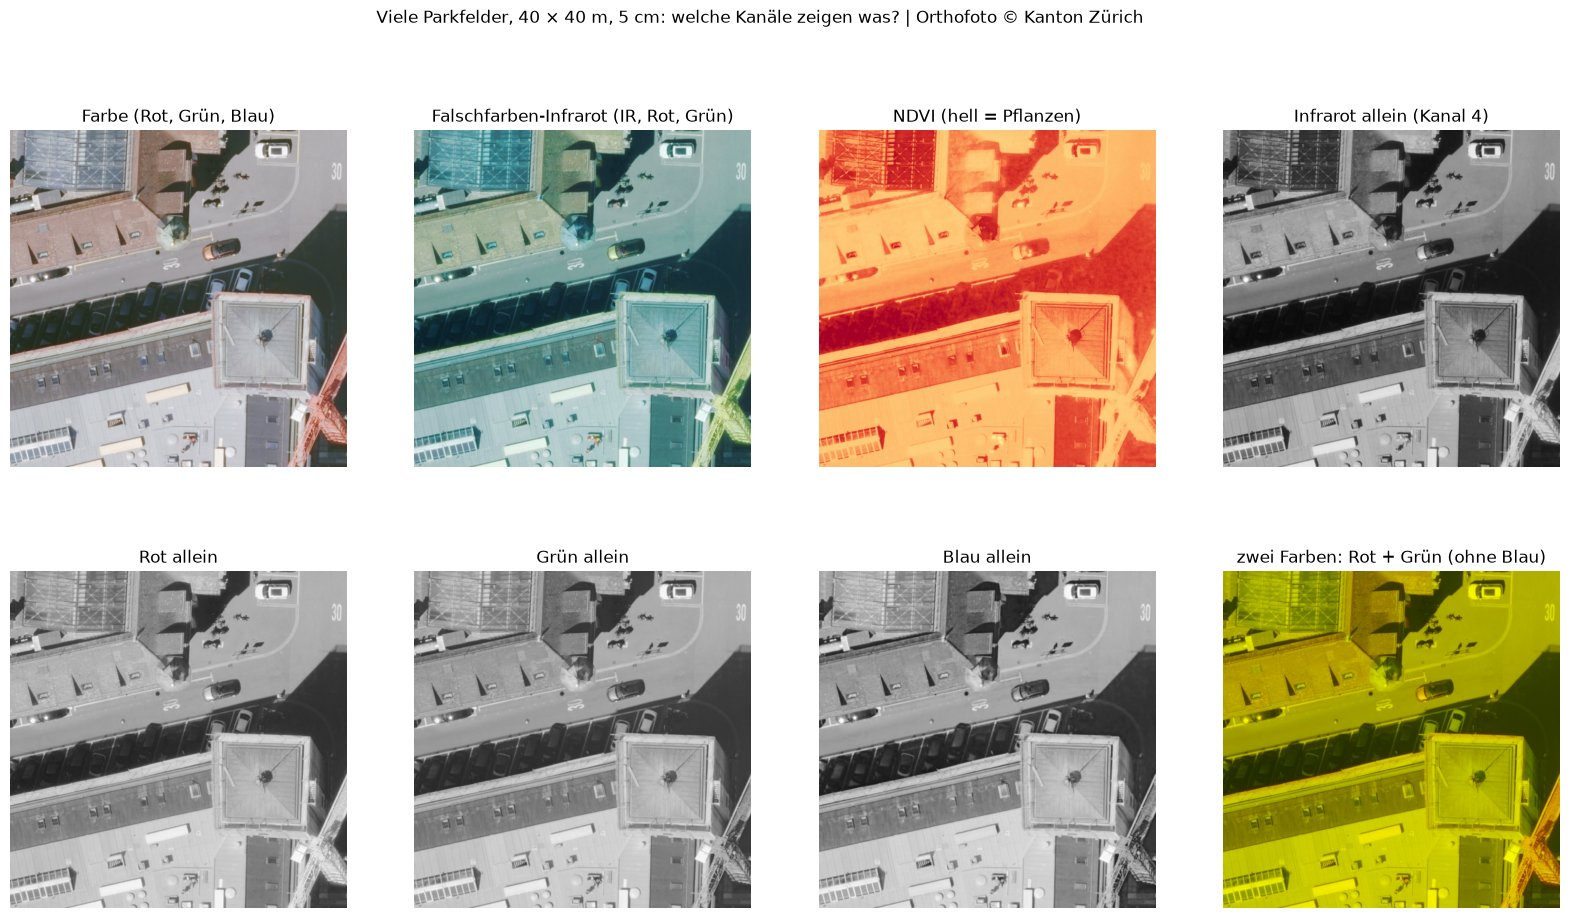

In [25]:
fig, axs = plt.subplots(2, 4, figsize=(20, 10.5))
zeige(axs[0, 0], dreikanal(rot, gruen, blau), "Farbe (Rot, Grün, Blau)")
zeige(axs[0, 1], dreikanal(infrarot, rot, gruen), "Falschfarben-Infrarot (IR, Rot, Grün)")
zeige(axs[0, 2], ndvi, "NDVI (hell = Pflanzen)", cmap="RdYlGn", vmin=-0.5, vmax=0.8)
zeige(axs[0, 3], infrarot, "Infrarot allein (Kanal 4)", cmap="gray", vmin=0, vmax=255)
zeige(axs[1, 0], rot, "Rot allein", cmap="gray", vmin=0, vmax=255)
zeige(axs[1, 1], gruen, "Grün allein", cmap="gray", vmin=0, vmax=255)
zeige(axs[1, 2], blau, "Blau allein", cmap="gray", vmin=0, vmax=255)
zeige(axs[1, 3], dreikanal(rot, gruen, np.zeros_like(rot)), "zwei Farben: Rot + Grün (ohne Blau)")
fig.suptitle("Viele Parkfelder, 40 × 40 m, 5 cm: welche Kanäle zeigen was? | Orthofoto © Kanton Zürich")
fig.savefig(ABB / "01_kanal_kombinationen.png", dpi=90, bbox_inches="tight")
plt.show()

## 11. Verfügbare Luftbilder im Vergleich

Für das Gebiet liegen drei Aufnahmen des Kantons vor (geladen mit `rohdaten_herunterladen.ipynb`):

| Ordner | Aufnahme | Auflösung |
| --- | --- | --- |
| `fruehjahr_2021` | Frühjahr 2021, laubfrei | 5 cm |
| `sommer_2024_25` | Sommer 2024/25 | 5 cm |
| `sommer_2026` | Sommer 2026 | 10 cm |

Wir schauen uns zuerst die technischen Angaben an, dann dieselben Stellen nebeneinander.

**Technische Angaben.** Eine GeoTIFF-Datei enthält neben den Pixeln eine Beschreibung: Anzahl Kanäle, Pixelgrösse und manchmal Zusatzangaben (*Tags*), z. B. ein Datum.

In [26]:
aufnahmen = {"Frühjahr 2021": ROH / "orthofoto" / "fruehjahr_2021",
             "Sommer 2024/25": ROH / "orthofoto" / "sommer_2024_25",
             "Sommer 2026": ROH / "orthofoto" / "sommer_2026"}
zeilen = []
for name, ordner in aufnahmen.items():
    dateien = sorted(ordner.glob("*.tif"))                           # alle Bilddateien dieser Aufnahme
    with rasterio.open(dateien[0]) as bild:                          # die erste Datei als Beispiel öffnen
        tags = bild.tags()                                           # Zusatzangaben der Datei (Wörterbuch)
        zeilen.append(dict(aufnahme=name, dateien=len(dateien), kanaele=bild.count,
                           pixel_m=round(bild.res[0], 3),
                           groesse_GB=round(sum(d.stat().st_size for d in dateien) / 1e9, 1),
                           datum_in_datei=tags.get("TIFFTAG_DATETIME", "–")))
pd.DataFrame(zeilen)

,aufnahme,dateien,kanaele,pixel_m,groesse_GB,datum_in_datei
0,Frühjahr 2021,6,4,0.05,19.4,–
1,Sommer 2024/25,9,4,0.05,8.1,–
2,Sommer 2026,9,4,0.10,5.1,–


**Dieselben Stellen nebeneinander.** Die neue Funktion `lies_aufnahme` macht dasselbe wie `lies_luftbild` von oben, bekommt aber zusätzlich den Ordner der Aufnahme. Drei Ausschnitte von 40 × 40 m um Parkfelder: einer an einer Strasse mit Bäumen (Hirschengraben), einer mit vielen Parkfeldern (Kappelergasse, wie in Abschnitt 10), einer zufällig gezogen. So sieht man Laub, Schatten, Schärfe und parkierte Autos im Vergleich.

In [27]:
def lies_aufnahme(ordner, rahmen, aufloesung_m):
    # wie lies_luftbild, aber aus einem beliebigen Ordner (einer anderen Aufnahme)
    kacheln = [rasterio.open(p) for p in sorted(ordner.glob("*.tif"))]
    bild, _ = merge(kacheln, bounds=rahmen, res=aufloesung_m, indexes=[1, 2, 3], resampling=Resampling.average)
    for k in kacheln:
        k.close()
    return bild

Drei Stellen, je in allen Aufnahmen: Zeilen sind die Orte, Spalten die Aufnahmen.

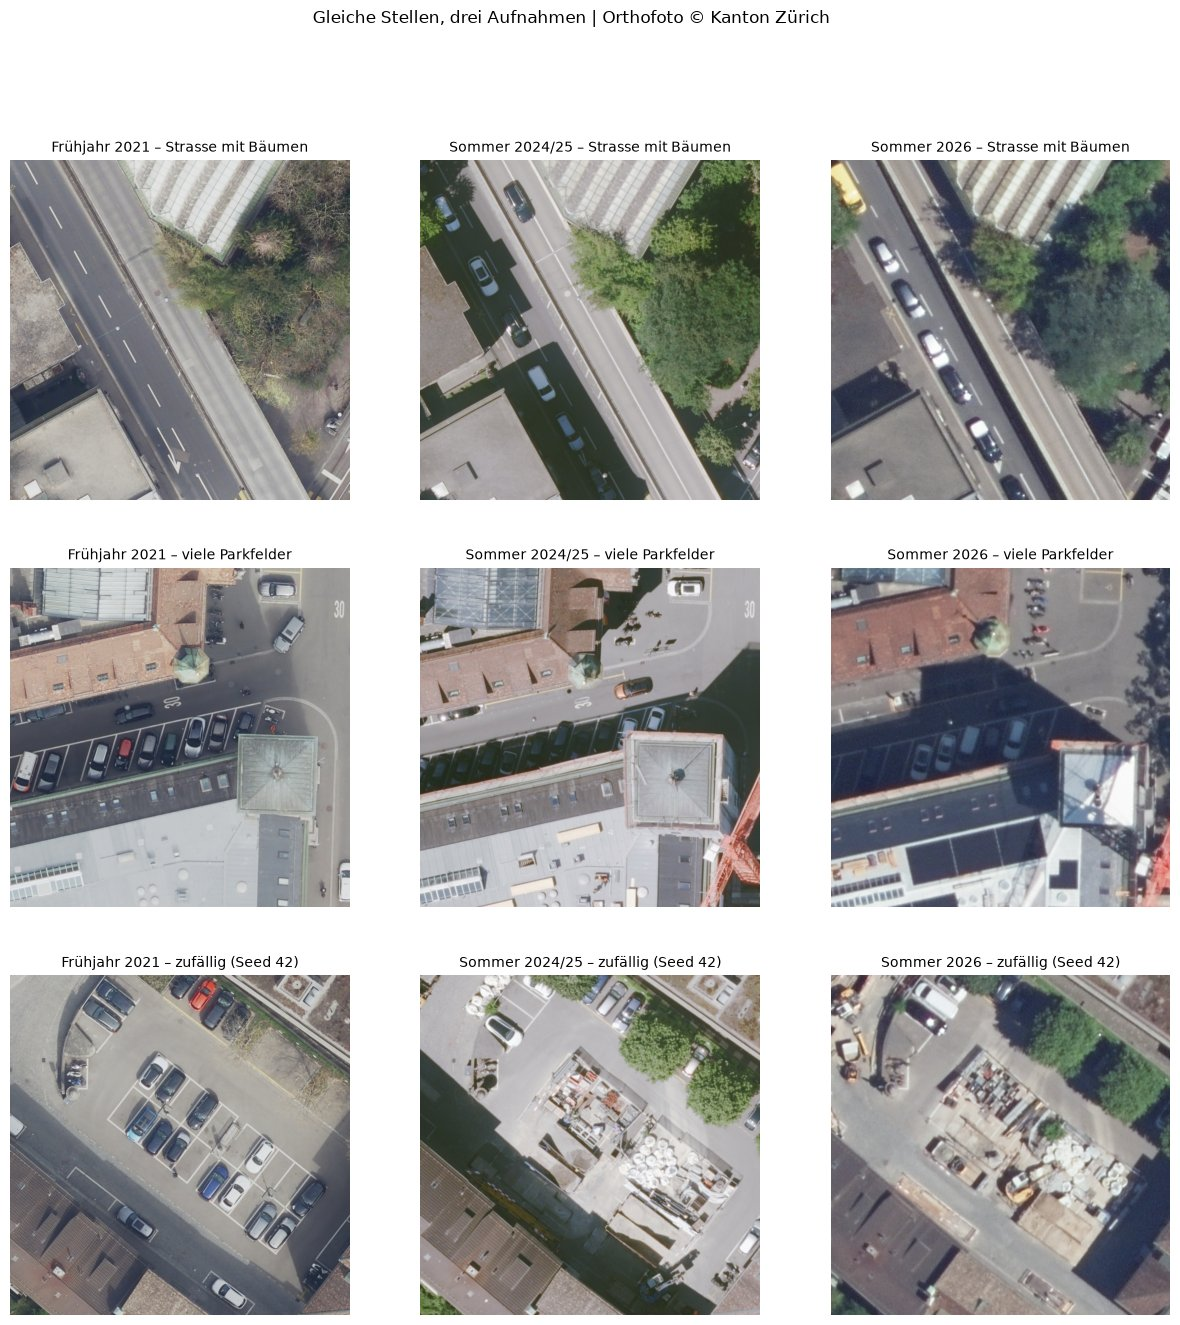

In [28]:
# Drei Mittelpunkte: ein Feld am Hirschengraben (Bäume), das erste Feld der Tabelle (Kappelergasse, viele Felder), ein zufälliges
import numpy as np
beispiele = {
    "Strasse mit Bäumen": dav_gebiet[dav_gebiet.bezeichnung.fillna("").str.contains("Hirschengraben")].geometry.iloc[0],
    "viele Parkfelder": dav_gebiet.geometry.iloc[0],
    "zufällig (Seed 42)": dav_gebiet.sample(1, random_state=42).geometry.iloc[0],
}
fig, axs = plt.subplots(len(beispiele), len(aufnahmen), figsize=(15, 15))    # Zeilen = Orte, Spalten = Aufnahmen
for zeile, (ort, punkt) in enumerate(beispiele.items()):
    rahmen = (punkt.x - 20, punkt.y - 20, punkt.x + 20, punkt.y + 20)      # 40 × 40 m um das Parkfeld
    for spalte, (name, ordner) in enumerate(aufnahmen.items()):
        pixel = 0.10 if "2026" in name else 0.05                           # jede Aufnahme in ihrer eigenen Auflösung
        bild = lies_aufnahme(ordner, rahmen, pixel)
        axs[zeile, spalte].imshow(bild.transpose(1, 2, 0))                 # [Kanäle, Zeilen, Spalten] -> [Zeilen, Spalten, Kanäle]
        axs[zeile, spalte].set_title(f"{name} – {ort}", fontsize=10)
        axs[zeile, spalte].set_axis_off()
fig.suptitle("Gleiche Stellen, drei Aufnahmen | Orthofoto © Kanton Zürich")
fig.savefig(ABB / "01_luftbilder_vergleich.png", dpi=90, bbox_inches="tight")
plt.show()

## 12. Stellen, an denen Parkfelder schwer zu sehen sind

Bis jetzt haben wir einzelne Stellen von Hand ausgewählt. Jetzt suchen wir **systematisch** Parkfelder, die im Luftbild schwierig sind, und solche, die leicht sind (als Vergleich). Dafür brauchen wir zwei einfache Messwerte je Parkfeld:

| Messwert | Formel | Bedeutung |
| --- | --- | --- |
| **NDVI** (Pflanzen-Index) | (Infrarot − Rot) ÷ (Infrarot + Rot) | über 0 = eher Pflanze (Baum), unter 0 = eher Asphalt, Dach |
| **Helligkeit** | (Rot + Grün + Blau) ÷ 3 | 0 = schwarz, 255 = weiss; tief = Schatten |

**Vorgehen in vier Schritten**
1. Das ganze Gebiet grob lesen (0,5 m statt 5 cm, sonst wäre das Bild 100-mal grösser).
2. NDVI und Helligkeit für jedes Pixel berechnen.
3. Für jedes Parkfeld den Mittelwert in einem Fenster von 5 × 5 Pixeln (2,5 × 2,5 m) um den DAV-Punkt nehmen.
4. Nach Regeln je ein Beispiel auswählen und in beiden Aufnahmen (Frühjahr 2021, Sommer 2024/25) zeigen.

In [29]:
# Schritt 1: ganzes Gebiet grob lesen, alle 4 Kanäle (Rot, Grün, Blau, Infrarot)
x_min, y_min, x_max, y_max = gebiet.bounds                         # Rechteck um das Gebiet
grob, grob_lage = lies_luftbild((x_min, y_min, x_max, y_max), 0.5, kanaele=(1, 2, 3, 4))
print("Bild des Gebiets:", grob.shape, "= (Kanäle, Zeilen, Spalten), 1 Pixel = 0,5 × 0,5 m")

Bild des Gebiets: (4, 4387, 3271) = (Kanäle, Zeilen, Spalten), 1 Pixel = 0,5 × 0,5 m


In [30]:
# Schritt 2: NDVI und Helligkeit für jedes Pixel
rot, gruen, blau, infrarot = grob.astype(float)                    # die 4 Kanäle als Kommazahlen (sonst rechnet Python mit 0–255 falsch)
ndvi = (infrarot - rot) / (infrarot + rot + 1e-6)                  # + 1e-6 verhindert Division durch 0 bei schwarzen Pixeln
helligkeit = (rot + gruen + blau) / 3                              # Mittel der drei Farbkanäle
print("NDVI von", ndvi.min().round(2), "bis", ndvi.max().round(2), "| Helligkeit von", helligkeit.min().round(), "bis", helligkeit.max().round())

NDVI von -0.83 bis 0.71 | Helligkeit von 0.0 bis 253.0


In [31]:
# Schritt 3: Werte bei jedem Parkfeld ablesen
from rasterio.transform import rowcol                              # Koordinate -> (Zeile, Spalte) im Bild

zeilen_px, spalten_px = rowcol(grob_lage, dav_gebiet.geometry.x.values, dav_gebiet.geometry.y.values)

def fenster_mittel(schicht, z, s):
    # Mittelwert im Fenster 5 × 5 Pixel um (z, s); max(..., 0) verhindert negative Indizes am Bildrand
    return schicht[max(z - 2, 0):z + 3, max(s - 2, 0):s + 3].mean()

felder = dav_gebiet[["bezeichnung", "orientierung", "art", "geometry"]].copy()   # Kopie: dav_gebiet bleibt unverändert
felder["ndvi"] = [fenster_mittel(ndvi, z, s) for z, s in zip(zeilen_px, spalten_px)]
felder["helligkeit"] = [fenster_mittel(helligkeit, z, s) for z, s in zip(zeilen_px, spalten_px)]

# Zusätzlich: wie viele andere Parkfelder liegen im Umkreis von 15 m? (0 = einzelnes Feld, viele = Reihe)
from scipy.spatial import cKDTree                                  # schnelle Suche nach nahen Punkten
xy = np.c_[felder.geometry.x, felder.geometry.y]                   # Tabelle mit 2 Spalten: x, y
nahe = cKDTree(xy).query_ball_point(xy, r=15)                      # für jedes Feld: Liste der Felder im Umkreis 15 m (inkl. sich selbst)
felder["nachbarn"] = [len(liste) - 1 for liste in nahe]            # - 1: das Feld selbst nicht mitzählen
felder["nachbar_ndvi_max"] = [felder.ndvi.values[liste].max() for liste in nahe]   # grünster Nachbar (Baum in der Reihe?)
felder[["ndvi", "helligkeit", "nachbarn"]].describe().round(2)

,ndvi,helligkeit,nachbarn
count,1252.00,1252.00,1252.00
mean,-0.12,114.57,6.73
std,0.21,51.43,4.49
min,-0.58,31.36,0.00
25%,-0.28,68.56,3.00
50%,-0.13,109.70,6.00
75%,-0.04,162.97,10.00
max,0.47,240.23,22.00


**Zwischenfrage: Wie viele Parkfelder liegen im Sommer unter einer Baumkrone?** Wir zählen die Felder, deren NDVI über einer Schwelle liegt. Weil unklar ist, ab welchem Wert man von "Baum" sprechen soll, zeigen wir drei Schwellen nebeneinander.

Dazu die Frage, wie viele **Gruppen** solche Felder bilden (mehrere verdeckte Felder nebeneinander = eine Gruppe). Das geht mit zwei bekannten Werkzeugen: Um jedes verdeckte Feld wird ein Kreis von 3,5 m gelegt (`buffer`); Kreise, die sich berühren, verschmelzen (`union_all`). Jede verbleibende Einzelfläche ist eine Gruppe.

In [32]:
zeilen = []
for schwelle in (0.1, 0.2, 0.3):
    unter_krone = felder[felder.ndvi > schwelle]                       # Maske und Auswahl: Felder über der Schwelle
    verschmolzen = unter_krone.geometry.buffer(3.5).union_all()        # Kreise um die Felder, zusammengewachsen
    gruppen = len(verschmolzen.geoms) if verschmolzen.geom_type == "MultiPolygon" else 1   # Anzahl Einzelflächen
    zeilen.append(dict(ndvi_ueber=schwelle, felder=len(unter_krone),
                       anteil_prozent=round(100 * len(unter_krone) / len(felder), 1), gruppen=gruppen))
print("Parkfelder im Gebiet:", len(felder))
pd.DataFrame(zeilen)

Parkfelder im Gebiet: 1252


,ndvi_ueber,felder,anteil_prozent,gruppen
0,0.1,196,15.7,80
1,0.2,133,10.6,60
2,0.3,70,5.6,33


**Schritt 4: Regeln für die Beispiele.** Jede Regel wählt das extremste Feld, das mindestens 60 m von den schon gewählten entfernt ist (damit nicht zweimal dieselbe Strasse erscheint).

Die Hilfsfunktion `waehle(maske, spalte, aufsteigend)` im Code unten macht genau das: `maske` ist die Bedingung (True/False je Feld), `spalte` der Messwert, nach dem sortiert wird, `aufsteigend=True` nimmt den kleinsten Wert zuerst, `False` den grössten. Vorher: 1'252 Parkfelder im Gebiet → nachher: 8 Beispielfelder.

| Fall | Regel |
| --- | --- |
| A unter Baum | höchster NDVI |
| B Reihe teils unter Baum | Feld selbst kein Baum (NDVI < −0,1), aber ein Nachbar mit Baum (NDVI > 0,25), mindestens 4 Nachbarn |
| C dunkel (Schatten) | kein Baum (NDVI < −0,05), mindestens 3 Nachbarn, tiefste Helligkeit |
| D zufällig (Seed 42) | dasselbe zufällige Feld wie in Abschnitt 11 |
| E freie Sicht | kein Baum (NDVI < −0,2), mindestens 5 Nachbarn, `Standard`, grösste Helligkeit |
| F einzelnes Feld | keine Nachbarn im Umkreis 15 m, `Standard`, grösste Helligkeit |
| G Gebäudeschatten | kein Baum beim Feld und bei den Nachbarn (NDVI < −0,15), tiefste Helligkeit |
| H Invalidenparkplatz | Art `Invalid`, grösste Helligkeit |

In [33]:
gewaehlt = []                                                      # Liste der schon gewählten Felder (Index)

def weit_genug(i):
    # True, wenn Feld i mindestens 60 m von allen schon gewählten Feldern entfernt ist
    return all(felder.geometry[i].distance(felder.geometry[j]) > 60 for j in gewaehlt)

Die zweite Funktion sortiert die Felder, die eine Bedingung erfüllen, und nimmt das erste, das weit genug von den schon gewählten entfernt ist:

In [34]:
def waehle(maske, spalte, aufsteigend):
    # Felder, die die Bedingung erfüllen, nach "spalte" sortieren und das erste nehmen, das weit genug weg ist
    for i in felder[maske].sort_values(spalte, ascending=aufsteigend).index:
        if weit_genug(i):
            gewaehlt.append(i)
            return i

Die acht Regeln, eine je Fall:

In [35]:
f = felder                                                         # kürzerer Name für die Regeln unten
faelle = {}
faelle["A unter Baum"] = waehle(f.ndvi > 0, "ndvi", False)
faelle["B Reihe teils unter Baum"] = waehle((f.ndvi < -0.1) & (f.nachbar_ndvi_max > 0.25) & (f.nachbarn >= 4), "nachbarn", False)
faelle["C dunkel (Schatten)"] = waehle((f.ndvi < -0.05) & (f.nachbarn >= 3), "helligkeit", True)
faelle["D zufällig (Seed 42)"] = dav_gebiet.sample(1, random_state=42).index[0]
gewaehlt.append(faelle["D zufällig (Seed 42)"])
faelle["E freie Sicht"] = waehle((f.ndvi < -0.2) & (f.nachbarn >= 5) & (f.art == "Standard"), "helligkeit", False)
faelle["F einzelnes Feld"] = waehle((f.nachbarn == 0) & (f.art == "Standard"), "helligkeit", False)
faelle["G Gebäudeschatten"] = waehle((f.ndvi < -0.15) & (f.nachbar_ndvi_max < -0.15), "helligkeit", True)
faelle["H Invalidenparkplatz"] = waehle(f.art == "Invalid", "helligkeit", False)

# Tabelle der gewählten Felder
tabelle = felder.loc[list(faelle.values()), ["bezeichnung", "orientierung", "art", "ndvi", "helligkeit", "nachbarn"]].round(2)
tabelle.insert(0, "fall", list(faelle.keys()))                     # Spalte "fall" vorne einfügen
tabelle

,fall,bezeichnung,orientierung,art,ndvi,helligkeit,nachbarn
71,A unter Baum,Auf der Mauer,LPU,Standard,0.47,68.43,3
6451,B Reihe teils unter Baum,Hirschengraben/Obergericht,QPU,Standard,-0.11,100.32,17
7203,C dunkel (Schatten),Hochtarif 2h Mo-Sa 9-20 Uhr,SCHPU,Standard,-0.07,31.36,8
4710,D zufällig (Seed 42),Untere Zäune,QPU,Standard,-0.12,150.27,19
237,E freie Sicht,Hirschengraben Nr. 42 - 84,SCHPU,Standard,-0.21,146.61,8
3524,F einzelnes Feld,Seidengasse,LPU,Standard,-0.28,91.15,0
107,G Gebäudeschatten,Basteiplatz,LPU,Standard,-0.38,35.45,4
979,H Invalidenparkplatz,NaN,QPU,Invalid,-0.04,205.01,1


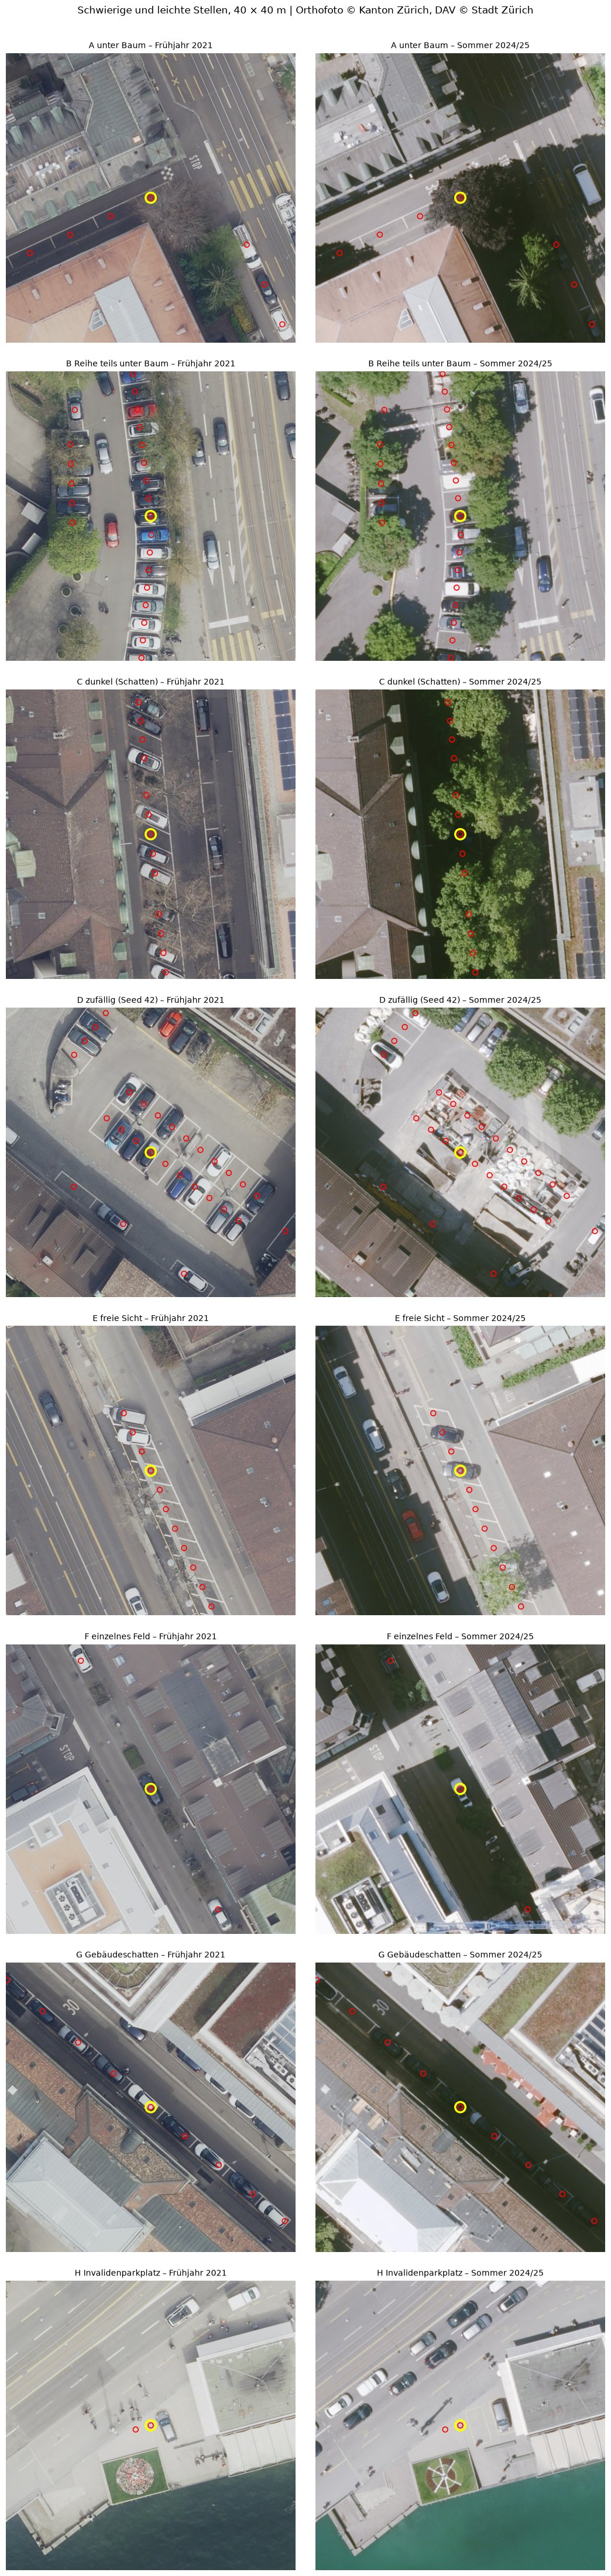

In [36]:
# Jeder Fall als Zeile, links Frühjahr 2021 (laubfrei), rechts Sommer 2024/25.
# Gelber Kreis = das eine Beispielfeld, das die Regel gewählt hat (keine Erkennung, noch kein Modell!).
# Rote Kreise = alle anderen DAV-Felder im Ausschnitt.
zwei = {"Frühjahr 2021": aufnahmen["Frühjahr 2021"], "Sommer 2024/25": aufnahmen["Sommer 2024/25"]}
fig, axs = plt.subplots(len(faelle), 2, figsize=(11, 5.5 * len(faelle)))
for zeile, (fall, i) in enumerate(faelle.items()):
    punkt = felder.geometry[i]
    rahmen = (punkt.x - 20, punkt.y - 20, punkt.x + 20, punkt.y + 20)          # 40 × 40 m
    im_rahmen = felder.cx[rahmen[0]:rahmen[2], rahmen[1]:rahmen[3]]          # .cx = Auswahl nach Koordinaten
    for spalte, (name, ordner) in enumerate(zwei.items()):
        ax = axs[zeile, spalte]
        bild = lies_aufnahme(ordner, rahmen, 0.05)
        # extent = welche Koordinaten die Bildränder haben -> Punkte lassen sich direkt in LV95 darüberlegen
        ax.imshow(bild.transpose(1, 2, 0), extent=(rahmen[0], rahmen[2], rahmen[1], rahmen[3]))
        ax.scatter(im_rahmen.geometry.x, im_rahmen.geometry.y, s=40, facecolors="none", edgecolors="red", linewidths=1.2)   # alle Felder
        ax.scatter([punkt.x], [punkt.y], s=160, facecolors="none", edgecolors="yellow", linewidths=2.5)                    # gewähltes Feld
        ax.set_title(f"{fall} – {name}", fontsize=10)
        ax.set_axis_off()
fig.suptitle("Schwierige und leichte Stellen, 40 × 40 m | Orthofoto © Kanton Zürich, DAV © Stadt Zürich", y=1.0)
fig.tight_layout()
fig.savefig(ABB / "01_schwierige_stellen.png", dpi=80, bbox_inches="tight")
plt.show()

**Was die Bilder zeigen** (nur Beobachtungen, die Entscheide folgen in `01b`). Wichtig: Je Fall ist genau **ein** Feld gelb markiert; oft sind auch die roten Nachbarn betroffen.
- **A:** Das Feld liegt im Sommer im Schatten eines Baumes (nicht unter der Krone); im Frühjahr 2021 ist die Stelle hell.
- **B, C:** Im Sommer verdecken Baumkronen einen Teil der Reihe bzw. fast die ganze Reihe; im Frühjahr 2021 sind dieselben Felder sichtbar.
- **C, G:** Dunkle Stellen: Schatten von Bäumen bzw. Gebäuden. Markierungen sind dort kaum erkennbar.
- **D:** Im Frühjahr 2021 ein Parkplatz mit Markierungen, im Sommer 2024/25 eine Baustelle – die DAV-Felder sind trotzdem eingetragen.
- **E:** Freie Sicht: weisse Linie entlang der Fahrbahn und kurze Querstriche dazwischen, das Muster wiederholt sich.
- **F:** Einzelnes Feld ohne Nachbarn: kein Muster, an dem man sich orientieren kann.
- **H:** Zwei Invalidenparkplätze; die DAV-Punkte liegen leicht neben den im Bild sichtbaren Feldern.

## 13. Felder mit einem Datum nach der Befliegung

**Worum es geht.** In Abschnitt 7 haben wir gesehen: Ein Teil der DAV-Felder trägt im Feld `inbetriebnahme` ein Datum, das **nach** der Befliegung liegt. Was dieses Datum bedeutet (neu gebaut oder nur neu erfasst), steht nirgends. Hier schauen wir uns solche Felder im Bild an. Mehr nicht: Wir beobachten, ein Entscheid folgt erst in `01b`.

**Wann wurde geflogen?** Die Bilddateien enthalten kein Datum (Abschnitt 11). Das amtliche Merkblatt zum Orthofoto 2024/25 (Kanton Zürich, 20.03.2025, Ordner `quellen/`) nennt 15 Flugtage zwischen dem **19.06.2024** und dem **22.09.2024**; damals waren 93 % der Fläche fertig, der Rest folgte 2025. Für welchen Tag das für Kreis 1 gilt, steht dort nicht. Wir zeigen deshalb zwei Grenzen: den letzten genannten Flugtag (22.09.2024) und den 1.1.2025 aus Abschnitt 7.

**Wie genau ist das Bild?** Dasselbe Merkblatt gibt an: Was auf dem Boden liegt (Strassen, Markierungen), lässt sich auf 1–2 Pixel genau abgreifen, also auf 5–10 cm.

**Ablauf.**
1. Felder mit spätem Datum zählen (Tabelle nach Monat und nach Ort).
2. 20 davon zufällig ziehen (fester Seed), mindestens 40 m auseinander.
3. Jedes dieser 20 Felder in allen drei Aufnahmen zeigen.

**Schritt 1: zählen.** Die Tabelle `felder` aus Abschnitt 12 bekommt eine neue Spalte `datum`.

In [37]:
felder["datum"] = pd.to_datetime(dav_gebiet.inbetriebnahme, errors="coerce")   # Text -> Datum, wie in Abschnitt 7

LETZTER_FLUGTAG = "2024-09-22"                                     # letzter Flugtag laut Merkblatt (Stand 20.03.2025)
spaet = felder[felder.datum > LETZTER_FLUGTAG]                     # Maske und Auswahl: Datum nach dem letzten Flugtag
print(f"Vorher: {len(felder)} Parkfelder im Gebiet")
print(f"Datum nach dem 22.09.2024: {len(spaet)} ({100 * len(spaet) / len(felder):.0f} %)")
print(f"Datum ab dem 01.01.2025:   {int((felder.datum >= '2025-01-01').sum())} ({100 * (felder.datum >= '2025-01-01').mean():.0f} %)")

Vorher: 1252 Parkfelder im Gebiet
Datum nach dem 22.09.2024: 461 (37 %)
Datum ab dem 01.01.2025:   390 (31 %)


**Wie verteilen sich die späten Daten?** Zwei Auszählungen mit `value_counts` (zählt, wie oft jeder Wert vorkommt):
- nach **Monat**: `.dt.to_period("M")` macht aus einem Datum den Monat (z. B. 2026-03);
- nach **Tag**: Wie viele Felder tragen genau dasselbe Datum?

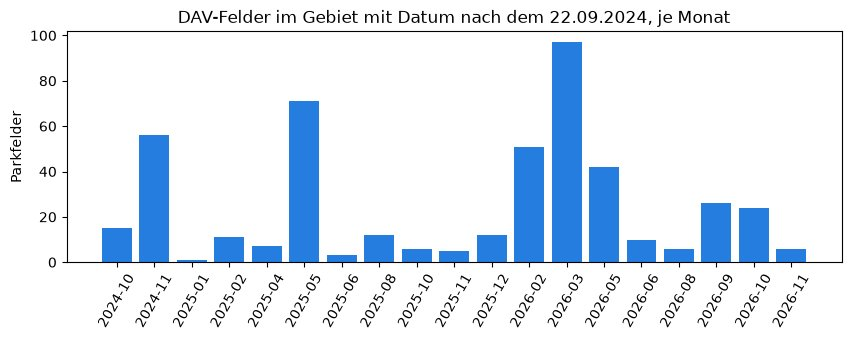

Verschiedene Tage: 33 | Felder am häufigsten Tag: 71


,felder
datum,
2025-05-07,71
2026-03-06,68
2024-11-08,56
2026-05-08,42
2026-09-07,26
2026-02-18,24
2026-02-24,21
2026-03-12,20


In [38]:
je_monat = spaet.datum.dt.to_period("M").value_counts().sort_index()          # Anzahl Felder je Monat
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(je_monat.index.astype(str), je_monat.values, color="#257de0")          # Balken: Monat -> Anzahl
ax.set_ylabel("Parkfelder")
ax.set_title("DAV-Felder im Gebiet mit Datum nach dem 22.09.2024, je Monat")
ax.tick_params(axis="x", rotation=60)                                         # Monatsnamen schräg stellen
fig.savefig(ABB / "01_datum_nach_befliegung.png", dpi=130, bbox_inches="tight")
plt.show()

je_tag = spaet.datum.dt.date.value_counts()                                   # Anzahl Felder je einzelnem Tag
print("Verschiedene Tage:", len(je_tag), "| Felder am häufigsten Tag:", int(je_tag.iloc[0]))
je_tag.head(8).rename("felder").to_frame()                                    # die acht häufigsten Tage als Tabelle

**Was die Abbildung zeigt.** Jeder Balken ist ein Monat, seine Höhe die Zahl der Felder mit einem Datum in diesem Monat. Monate ohne solche Felder fehlen auf der Achse. Die späten Daten verteilen sich nicht gleichmässig: Wenige Monate tragen die meisten Felder, am meisten der März 2026 mit knapp 100 und der Mai 2025 mit rund 70. Die Tabelle darunter zeigt dasselbe nach Tagen: Die Felder verteilen sich auf wenige Tage, und am häufigsten Tag tragen 71 Felder dasselbe Datum.

In [39]:
# Dieselben Felder nach Ort (bezeichnung) und nach Art – jeweils die häufigsten Werte
print(spaet.bezeichnung.fillna("(ohne Ortsangabe)").value_counts().head(8).to_string())
print()
print(spaet.art.value_counts().to_string())

bezeichnung
Hochtarif 2h Mo-Sa 9-20 Uhr    178
Hirschengraben/Obergericht      70
Stadthausquai                   56
(ohne Ortsangabe)               53
Poststrasse                     14
Börsenstrasse Nr. 10 - 18       10
Hochtarif 3h Mo-Sa 9-20 Uhr      9
Beatenplatz                      8

art
Standard         404
Güterumschlag     22
Taxi              21
Invalid            9
Elektro            4
Car                1


**Schritt 2: 20 Felder ziehen.** `sample(frac=1, random_state=42)` mischt die Tabelle zufällig, aber immer gleich (Seed 42). Wir gehen die gemischte Liste durch und nehmen jedes Feld, das mindestens 40 m von den schon gezogenen entfernt ist, bis wir 20 haben. Der Abstand verhindert, dass zwanzigmal dieselbe Parkreihe erscheint.

Vorher: alle Felder mit spätem Datum → nachher: 20 Stichprobenfelder.

In [40]:
gezogen = []                                                       # Index der gezogenen Felder
for i in spaet.sample(frac=1, random_state=42).index:              # gemischte Reihenfolge
    weit_weg = all(felder.geometry[i].distance(felder.geometry[j]) >= 40 for j in gezogen)
    if weit_weg:
        gezogen.append(i)
    if len(gezogen) == 20:                                         # genug gezogen
        break

stichprobe = felder.loc[gezogen, ["bezeichnung", "orientierung", "art", "datum", "ndvi"]].copy()
stichprobe.insert(0, "nr", range(1, len(stichprobe) + 1))          # laufende Nummer 1 bis 20
stichprobe["datum"] = stichprobe.datum.dt.strftime("%d.%m.%Y")     # Datum als Text Tag.Monat.Jahr
stichprobe["ndvi"] = stichprobe.ndvi.round(2)
print(f"Vorher: {len(spaet)} Felder mit spätem Datum → nachher: {len(stichprobe)} Stichprobenfelder")
stichprobe

Vorher: 461 Felder mit spätem Datum → nachher: 20 Stichprobenfelder

,nr,bezeichnung,orientierung,art,datum,ndvi
6655,1,Hochtarif 2h Mo-Sa 9-20 Uhr,QPU,Standard,18.02.2026,-0.04
4279,2,Löwenstrasse Nr. 1 - 3,QPU,Standard,14.08.2025,-0.01
4355,3,Neumühlequai,LPU,Standard,23.10.2025,-0.12
6342,4,Stadthausquai,QPU,Standard,08.11.2024,0.06
6469,5,Hirschengraben/Obergericht,QPU,Standard,07.05.2025,0.04
8238,6,Hochtarif 2h Mo-Sa 9-20 Uhr,QPU,Standard,20.10.2026,0.33
13021,7,NaN,LPU,Taxi,07.09.2026,-0.12
12792,8,NaN,LPU,Güterumschlag,11.06.2026,0.36
12720,9,NaN,LPU,Güterumschlag,16.12.2025,-0.08
7455,10,Hochtarif 2h Mo-Sa 9-20 Uhr,SCHPU,Standard,06.03.2026,0.07


**Schritt 3: ansehen.** Je Feld eine Zeile mit drei Bildern von 24 × 24 m: Frühjahr 2021, Sommer 2024/25, Sommer 2026 (10 cm, darum unschärfer).

- **Gelber Kreis:** das gezogene Feld. Er hat einen Radius von genau **1 m** – daran lässt sich abschätzen, wie weit der DAV-Punkt neben der Markierung liegt. `Circle` zeichnet einen Kreis in Metern (nicht in Bildschirmpunkten wie `scatter`).
- **Rote Kreise:** alle anderen DAV-Felder im Ausschnitt, egal mit welchem Datum.
- Wie in Abschnitt 12 ist nichts davon eine Erkennung; es ist noch kein Modell im Spiel.

Die 20 Felder sind auf vier Abbildungen zu je fünf verteilt, damit die Bilder gross genug bleiben.

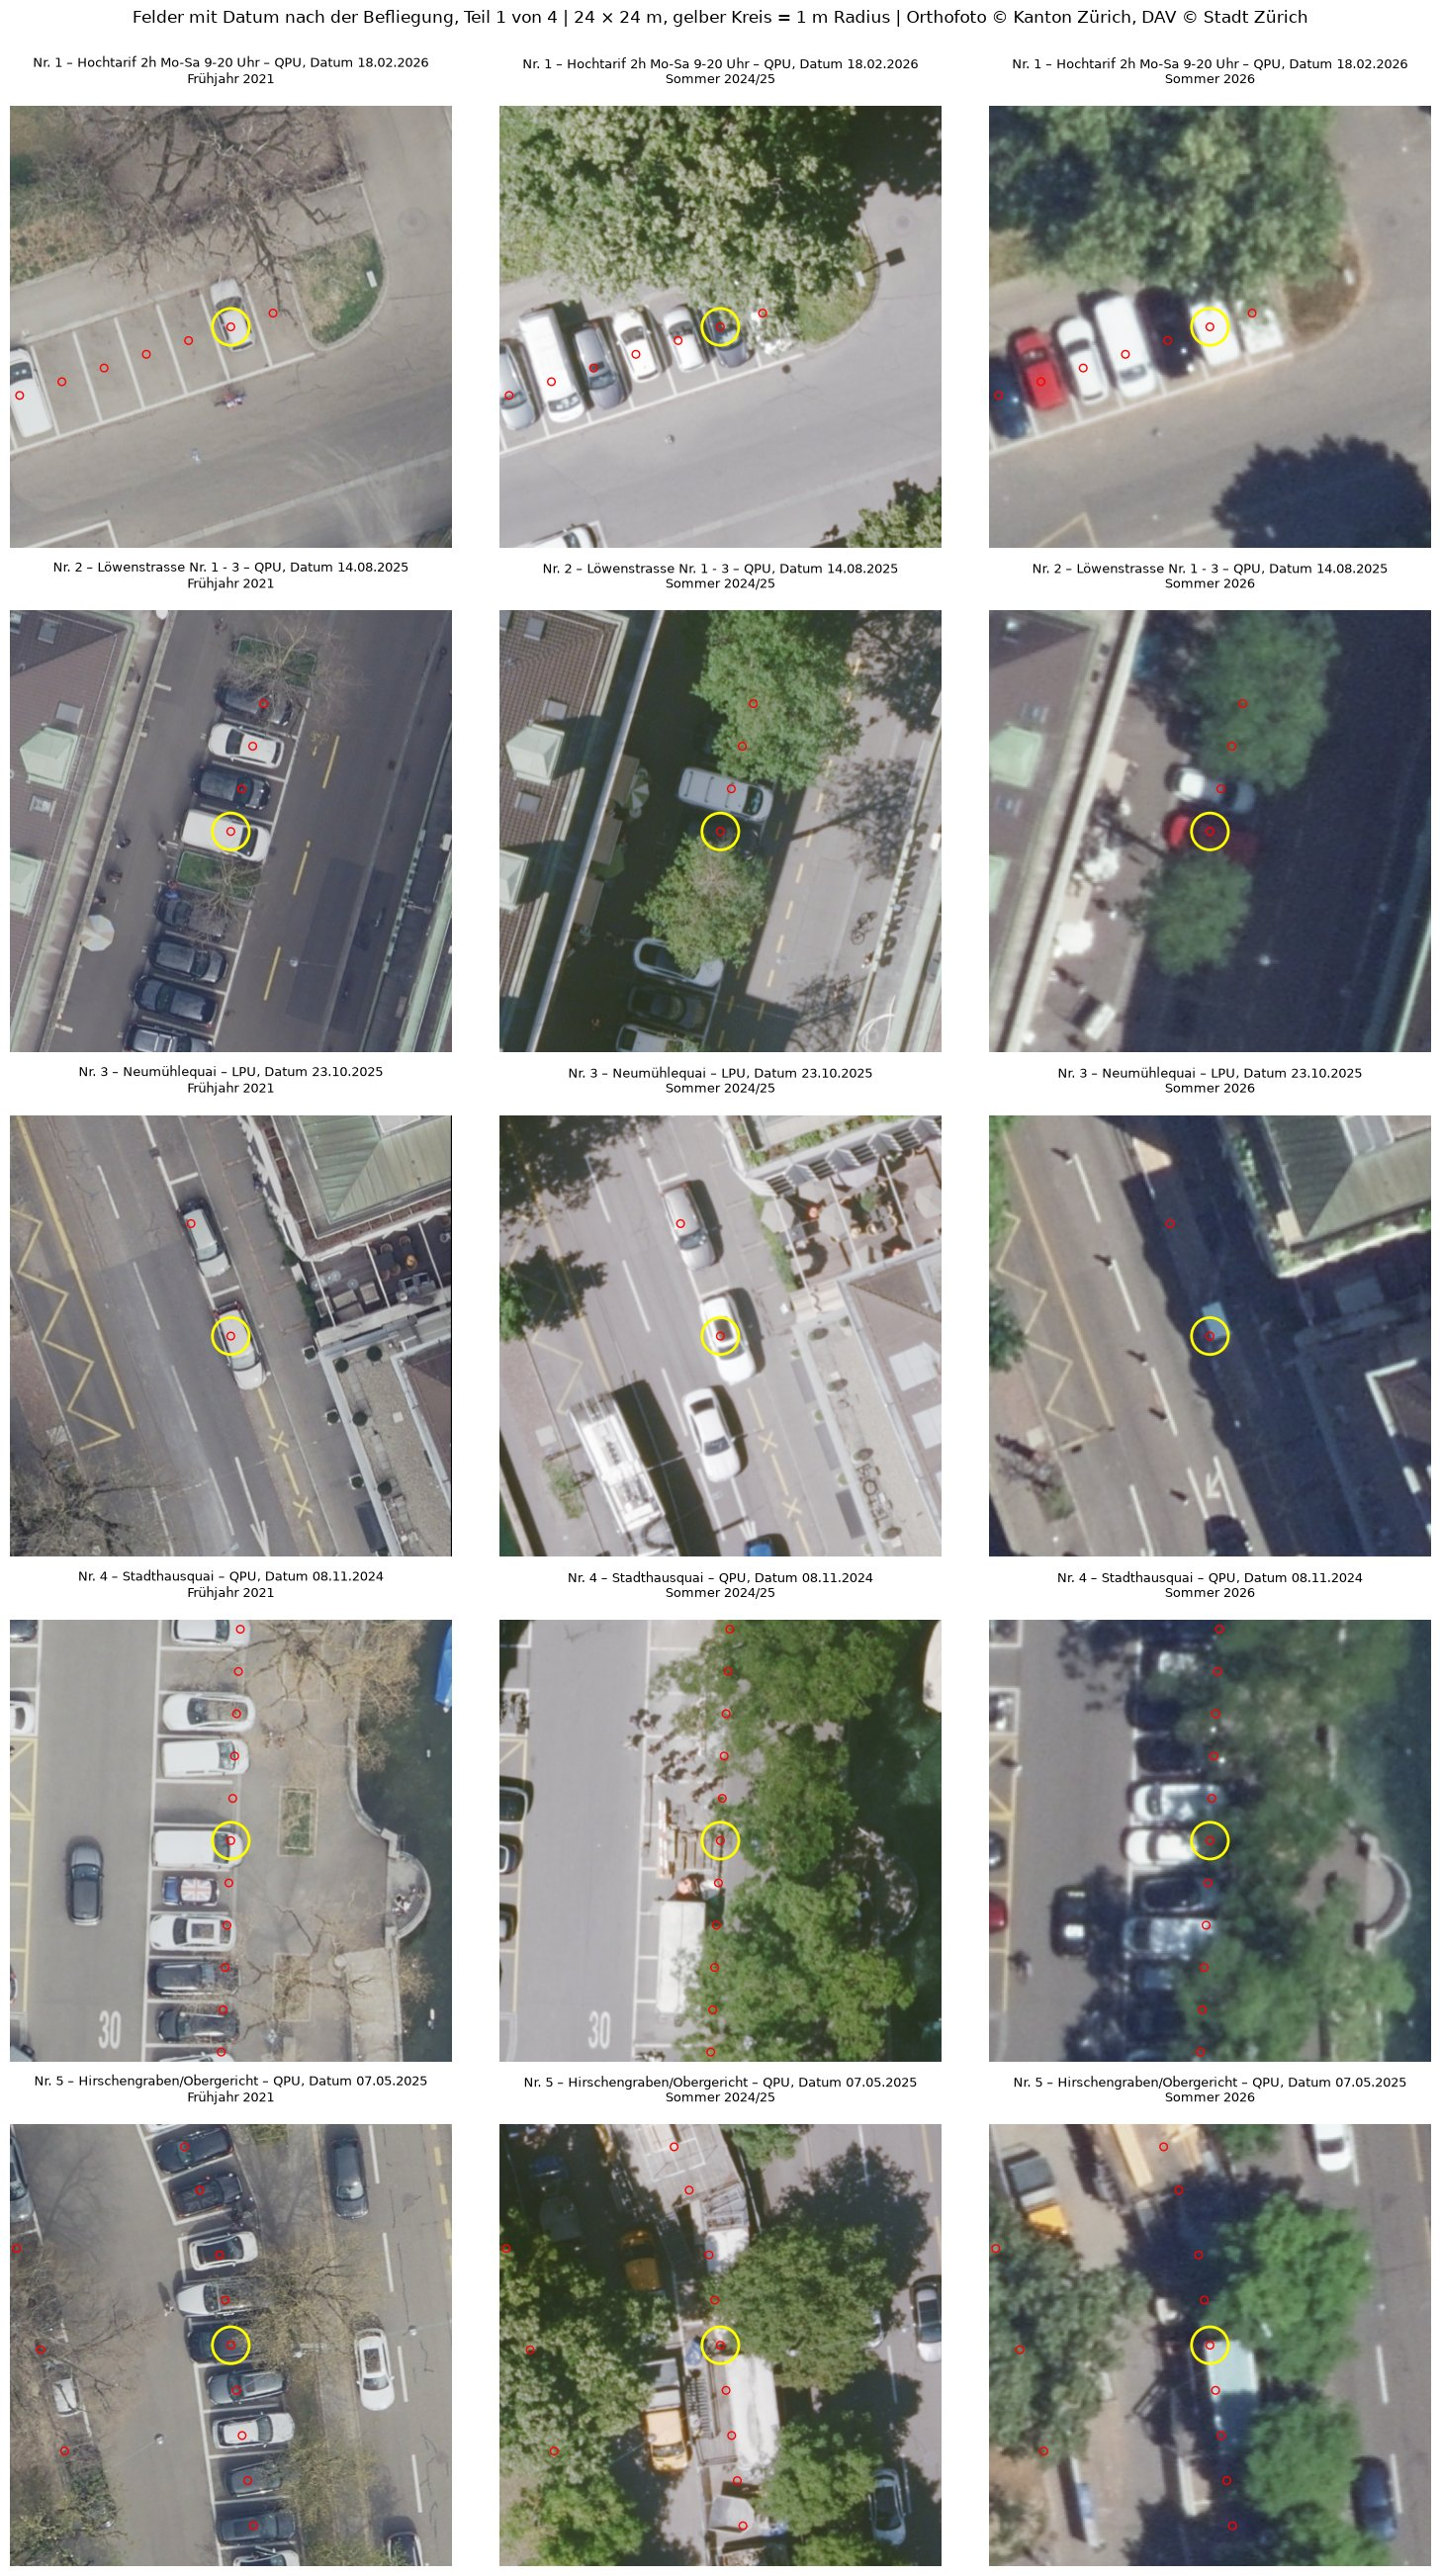

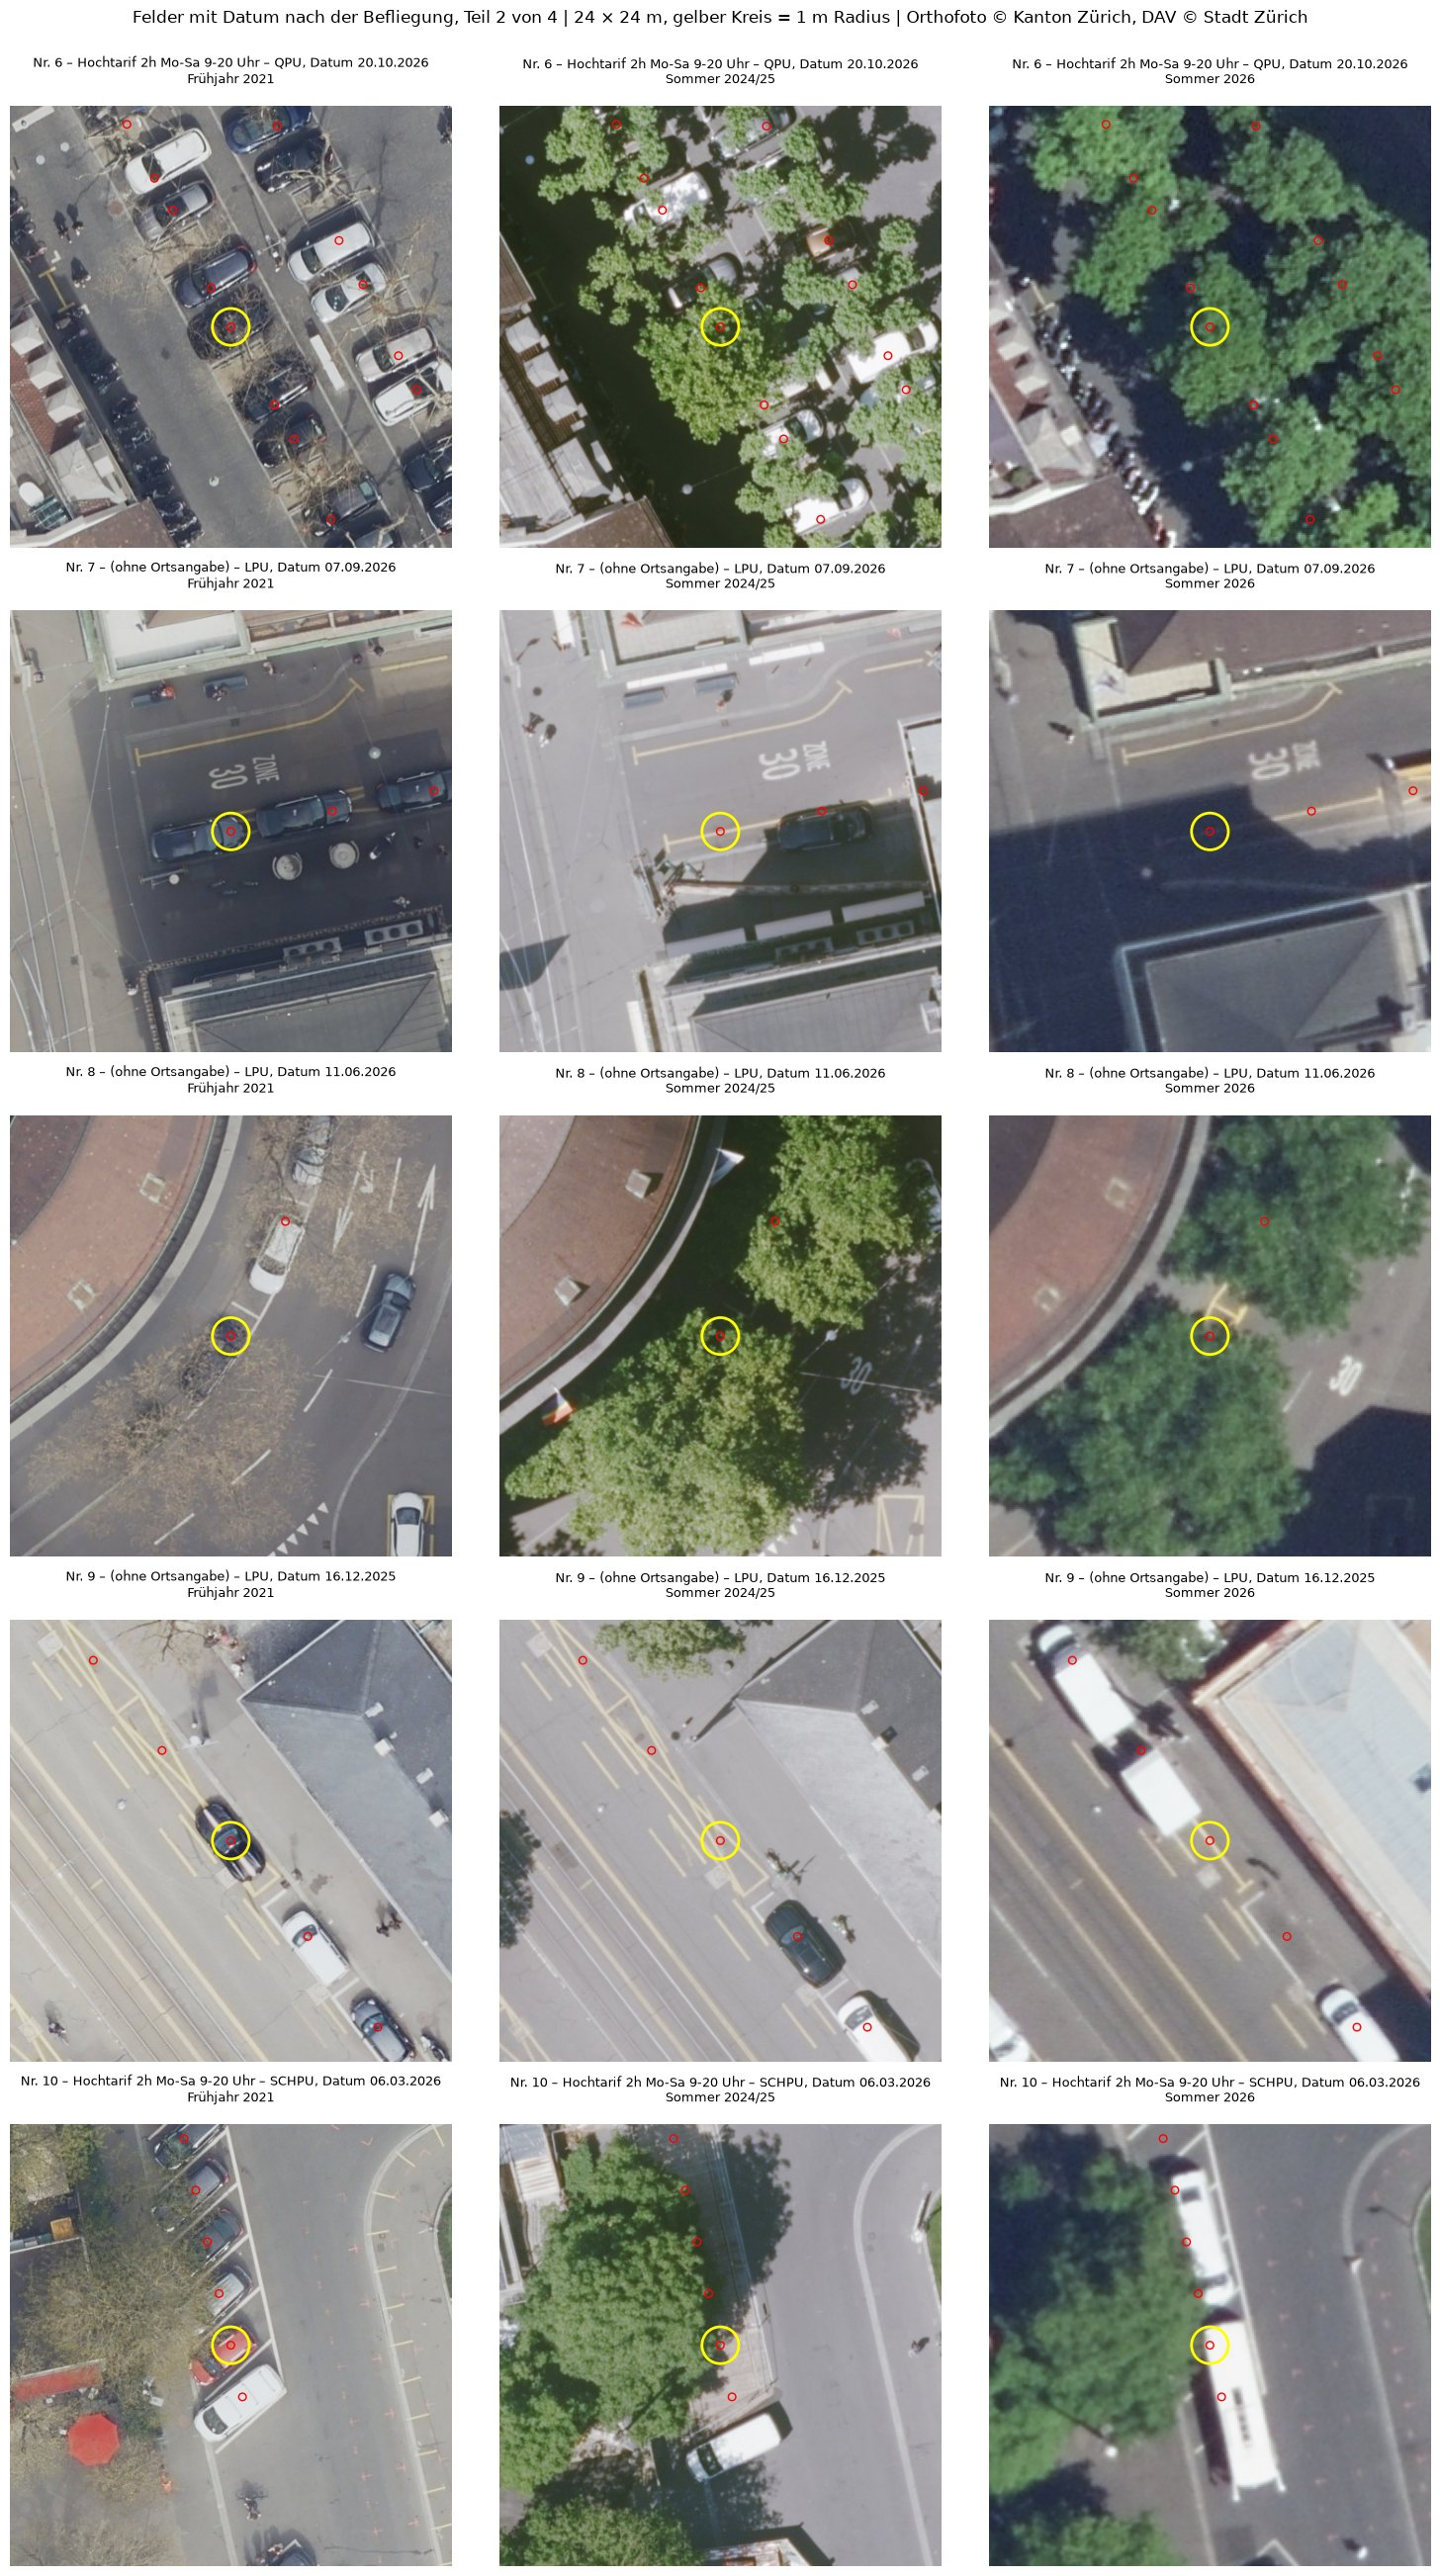

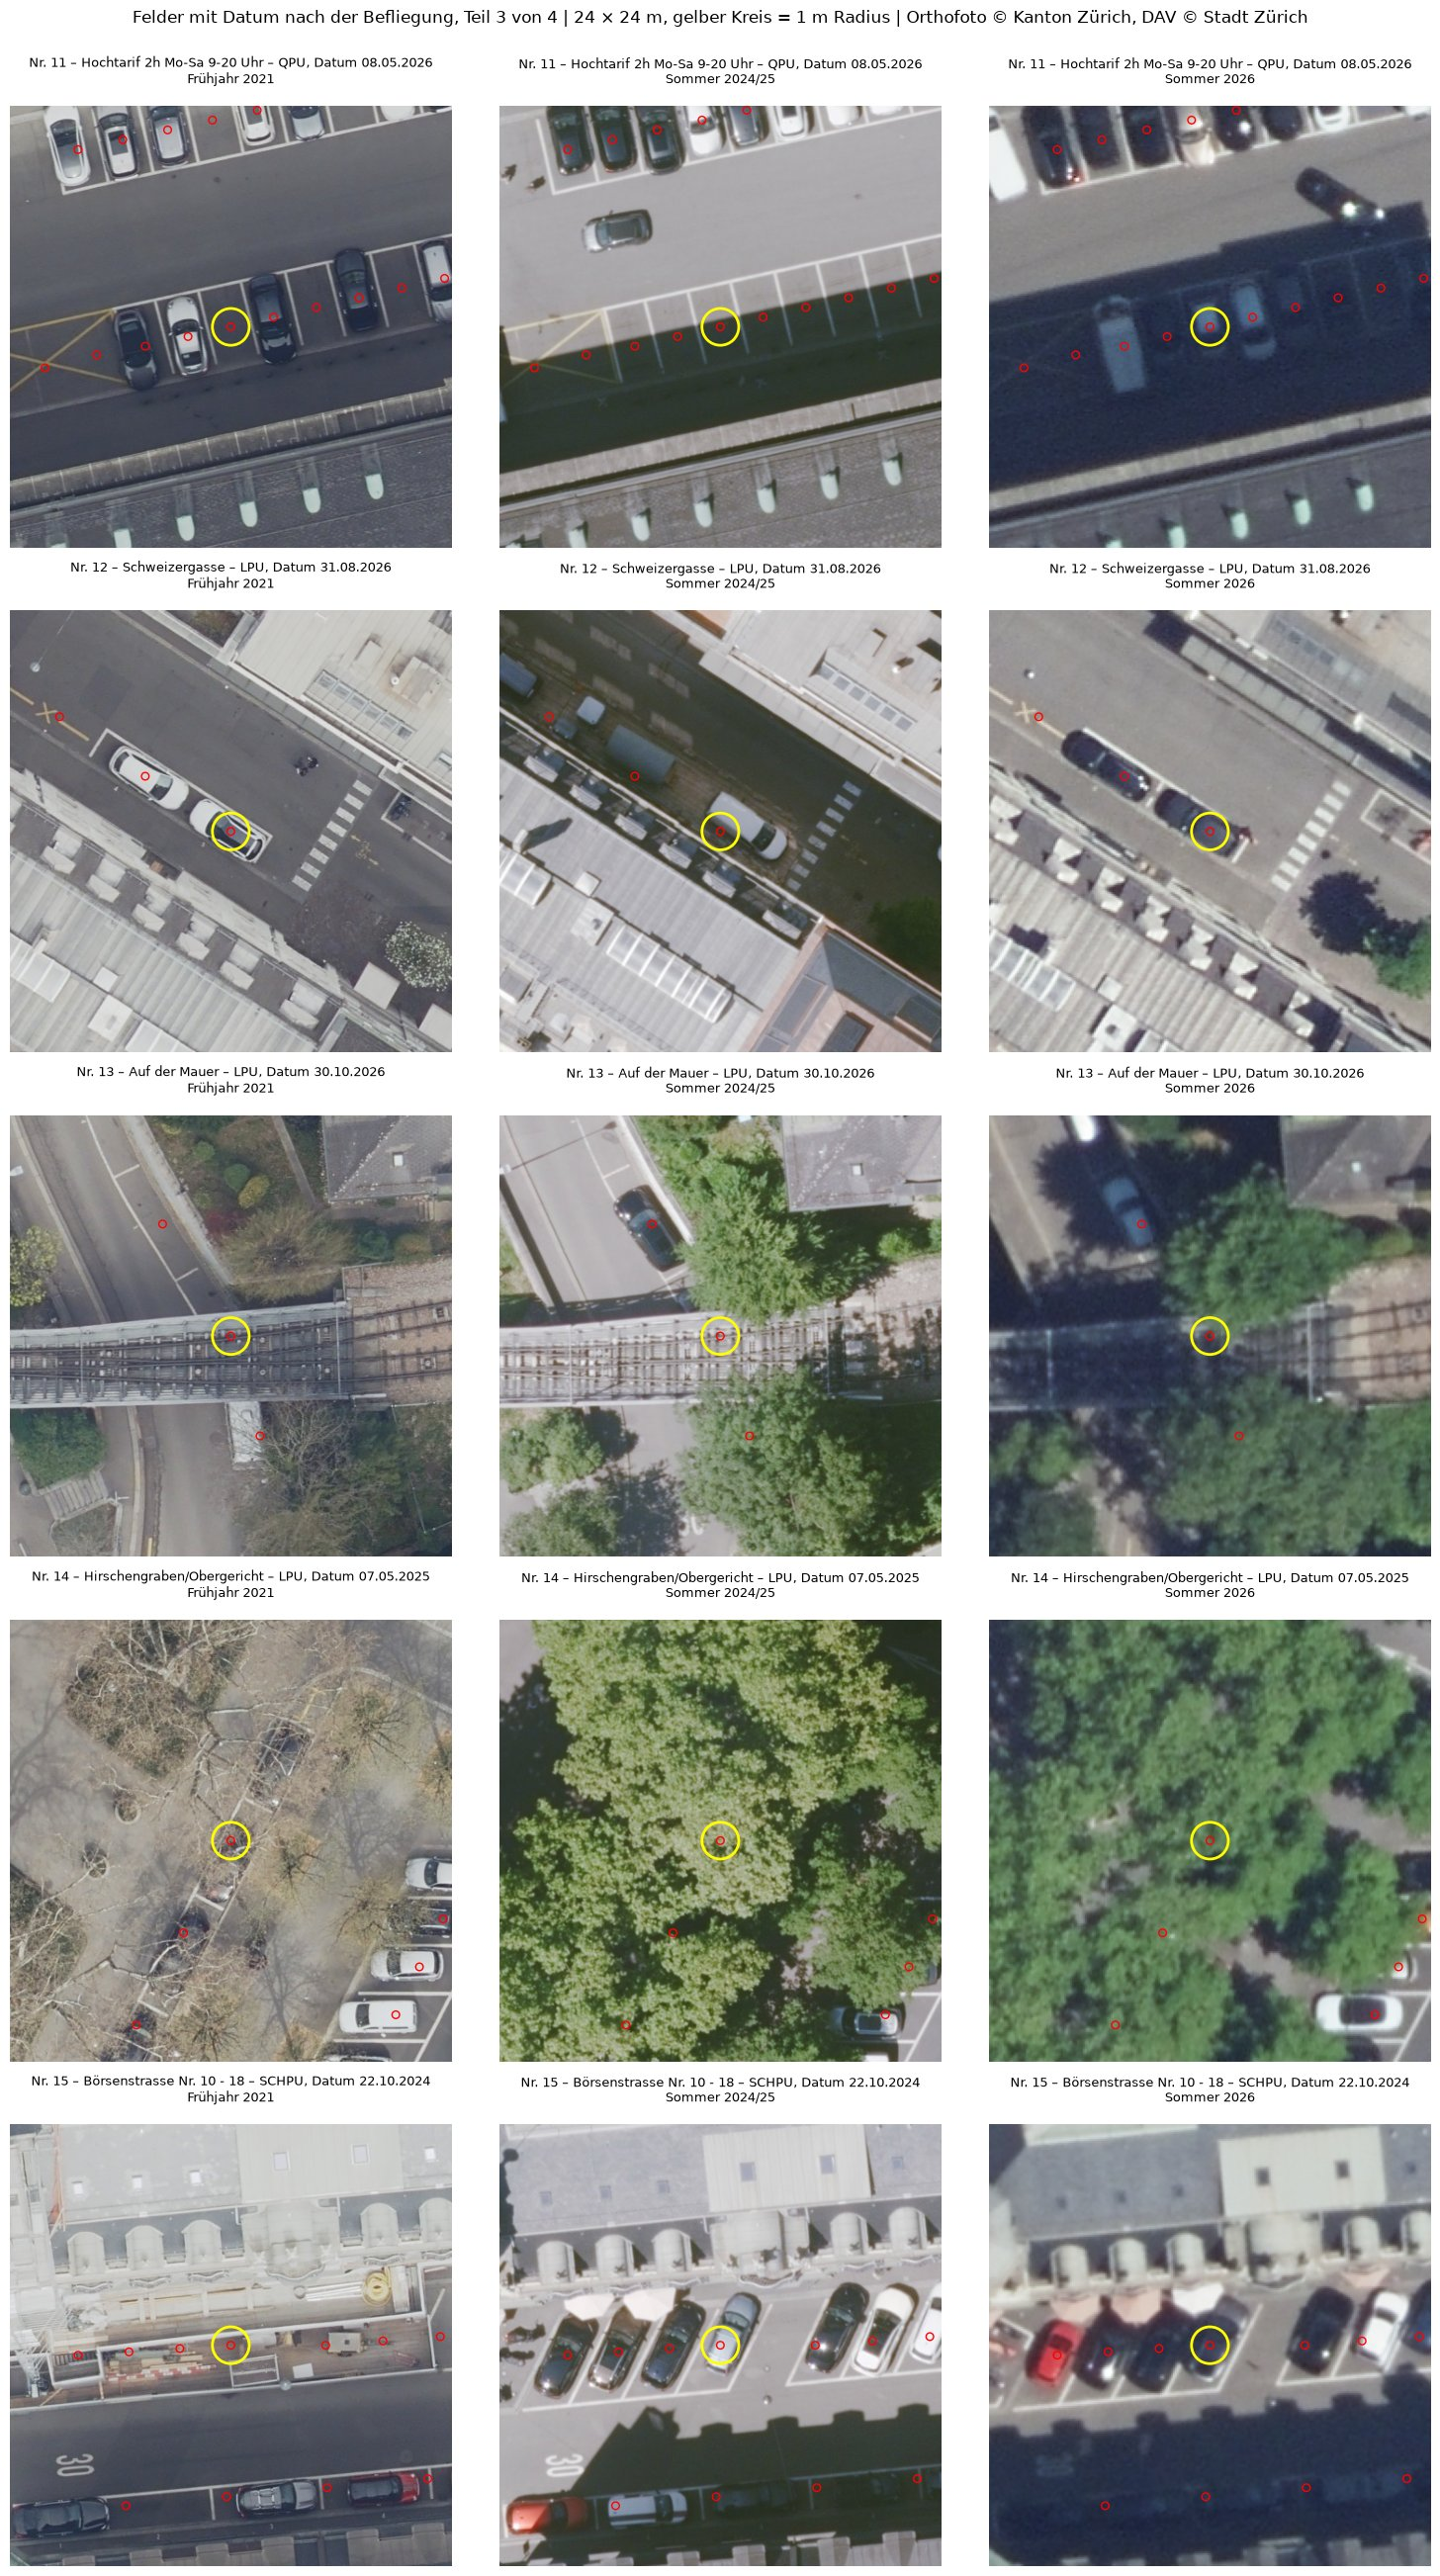

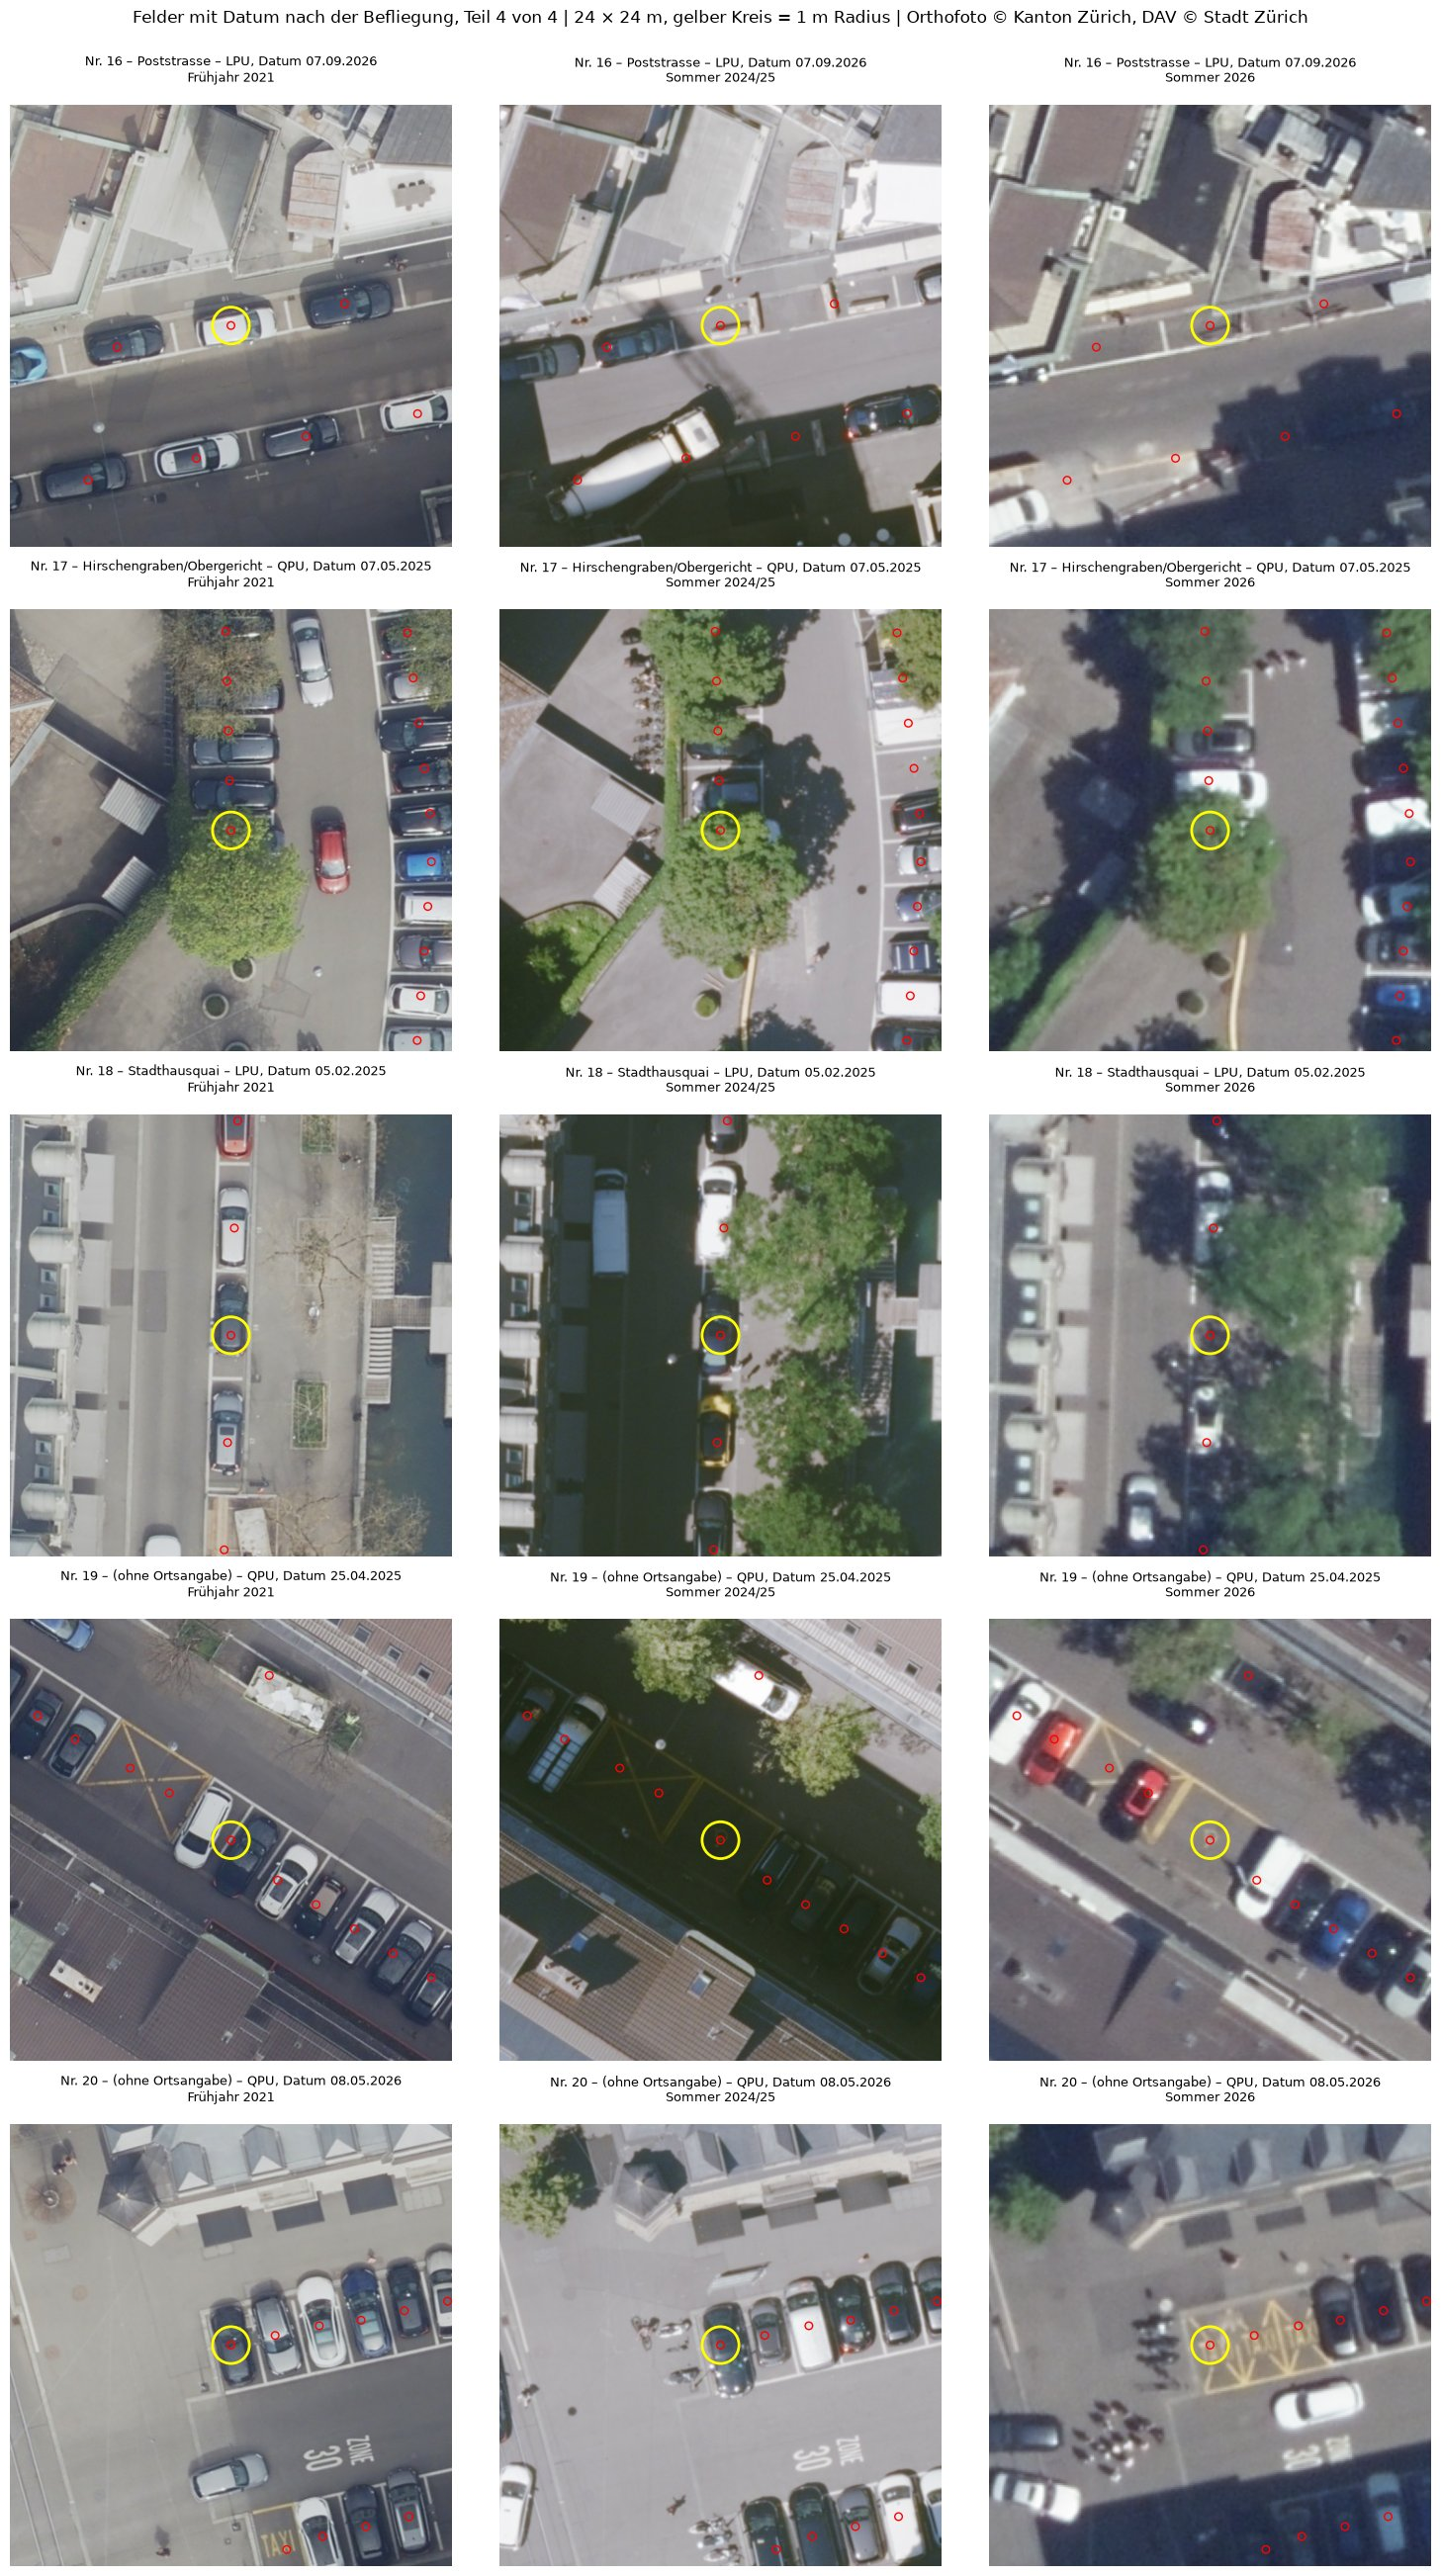

In [41]:
from matplotlib.patches import Circle                              # Kreis mit Radius in Metern

for teil in range(4):                                              # 4 Abbildungen zu je 5 Feldern
    gruppe = stichprobe.iloc[teil * 5:(teil + 1) * 5]              # Zeilen 0–4, 5–9, 10–14, 15–19
    fig, axs = plt.subplots(len(gruppe), 3, figsize=(15, 5.2 * len(gruppe)))
    for zeile, (i, feld) in enumerate(gruppe.iterrows()):
        punkt = felder.geometry[i]
        rahmen = (punkt.x - 12, punkt.y - 12, punkt.x + 12, punkt.y + 12)        # 24 × 24 m
        im_rahmen = felder.cx[rahmen[0]:rahmen[2], rahmen[1]:rahmen[3]]          # alle DAV-Felder im Ausschnitt
        for spalte, (name, ordner) in enumerate(aufnahmen.items()):
            ax = axs[zeile, spalte]
            pixel = 0.10 if "2026" in name else 0.05                             # jede Aufnahme in ihrer eigenen Auflösung
            bild = lies_aufnahme(ordner, rahmen, pixel)
            ax.imshow(bild.transpose(1, 2, 0), extent=(rahmen[0], rahmen[2], rahmen[1], rahmen[3]))
            ax.scatter(im_rahmen.geometry.x, im_rahmen.geometry.y, s=30, facecolors="none", edgecolors="red", linewidths=1.0)
            ax.add_patch(Circle((punkt.x, punkt.y), 1.0, fill=False, edgecolor="yellow", linewidth=2))   # Radius 1 m
            ort = feld.bezeichnung if isinstance(feld.bezeichnung, str) else "(ohne Ortsangabe)"
            ax.set_title(f"Nr. {feld.nr} – {ort} – {feld.orientierung}, Datum {feld.datum}\n{name}", fontsize=9)
            ax.set_axis_off()
    fig.suptitle(f"Felder mit Datum nach der Befliegung, Teil {teil + 1} von 4 | 24 × 24 m, gelber Kreis = 1 m Radius | "
                 "Orthofoto © Kanton Zürich, DAV © Stadt Zürich", y=1.0)
    fig.tight_layout()
    fig.savefig(ABB / f"01_nach_befliegung_{teil + 1}.png", dpi=80, bbox_inches="tight")
    plt.show()

**Worauf man bei jedem der 20 Felder achten kann** (die Beurteilung macht der Auftraggeber; sie wird in `01b` festgehalten):
1. Ist beim gelben Kreis im Bild **Sommer 2024/25** ein markiertes Parkfeld zu sehen?
2. War es schon im **Frühjahr 2021** da – also lange vor dem Datum der DAV?
3. Ist es im **Sommer 2026** zu sehen?
4. Liegt der gelbe Kreis **auf** dem Feld, oder ist er versetzt – und um etwa wie viel (der Kreis hat 1 m Radius)?

**Schritt 4: die Beurteilung des Auftraggebers auszählen.** Der Auftraggeber hat alle 20 Felder in allen drei Aufnahmen von Auge beurteilt (26.11.2026). Seine Antworten sind in festen Wörtern in der Datei `daten/ground_truth/sichtpruefung_nach_befliegung.csv` abgelegt: eine Zeile je Feld und Aufnahme, also 60 Zeilen. Was jede Spalte und jedes Wort bedeutet, steht in `01b_methodik_leitfaden`, Abschnitt 9.

Das ist eine **Beobachtung von Hand an 20 von 461 Feldern**, keine Messung über alle Felder.

`pivot` stellt die Tabelle um: eine Zeile je Feld, eine Spalte je Aufnahme.

In [42]:
SICHT = ROOT / "daten" / "ground_truth" / "sichtpruefung_nach_befliegung.csv"
sicht = pd.read_csv(SICHT, dtype=str, keep_default_na=False)       # alles als Text lesen, leere Zellen bleiben leer
sicht["nr"] = sicht.nr.astype(int)                                 # Nummer als Zahl, damit richtig sortiert wird
print(f"{len(sicht)} Zeilen = {sicht.nr.nunique()} Felder × {sicht.aufnahme.nunique()} Aufnahmen")

# Prüfung: In jeder Spalte dürfen nur die festgelegten Wörter stehen (Liste aus 01b, Abschnitt 9)
erlaubt = {
    "aufnahme": ["Frühjahr 2021", "Sommer 2024/25", "Sommer 2026"],
    "form": ["Einzelfeld", "gelbes Feld mit Kreuz", "Streifen ohne Einzelfelder", "unklar"],
    "markierung": ["ganz sichtbar", "teilweise sichtbar", "nicht sichtbar", "kein Parkfeld", "unklar"],
    "verdeckt_anteil": ["0", "unter 1/3", "1/3 bis 2/3", "über 2/3", "ganz", "nicht geschätzt"],
    "verdeckt_durch": ["nichts", "Äste ohne Laub", "Baumkrone", "Brücke", "Brücke und Baumkrone",
                       "Baustelle", "Baustelle und Baumkrone", "anderes"],
    "schatten": ["kein", "leicht", "stark"],
    "schatten_anteil": ["0", "unter 1/3", "1/3 bis 2/3", "über 2/3", "ganz", "nicht angegeben"],
    "zustand": ["sichtbar", "verdeckt, belegt", "verdeckt", "unsicher", "kein Parkfeld"],
    "beleg": ["nicht nötig", "anderes Luftbild", "amtliche Daten", "keiner"],
    "punktlage": ["im Feld", "auf der Linie", "ausserhalb", "kein Feld sichtbar"],
}
for spalte, woerter in erlaubt.items():
    fremd = sorted(set(sicht[spalte]) - set(woerter))               # Wörter, die nicht auf der Liste stehen
    assert not fremd, f"Spalte {spalte}: unbekannte Wörter {fremd}"
assert (sicht.groupby("nr").size() == 3).all()                     # jedes Feld genau dreimal (drei Aufnahmen)
print("Alle Spalten enthalten nur festgelegte Wörter; jedes Feld hat drei Zeilen.")

60 Zeilen = 20 Felder × 3 Aufnahmen
Alle Spalten enthalten nur festgelegte Wörter; jedes Feld hat drei Zeilen.


In [43]:
# Zustand je Feld (Zeile) und Aufnahme (Spalte)
je_feld = sicht.pivot(index="nr", columns="aufnahme", values="zustand")
je_feld

aufnahme,Frühjahr 2021,Sommer 2024/25,Sommer 2026
nr,,,
1,sichtbar,sichtbar,sichtbar
2,sichtbar,sichtbar,sichtbar
3,sichtbar,sichtbar,unsicher
4,sichtbar,sichtbar,sichtbar
5,sichtbar,unsicher,unsicher
6,sichtbar,"verdeckt, belegt","verdeckt, belegt"
7,sichtbar,sichtbar,sichtbar
8,sichtbar,"verdeckt, belegt","verdeckt, belegt"
9,sichtbar,sichtbar,sichtbar


In [44]:
# Wie oft kommt jeder Zustand je Aufnahme vor? (crosstab zählt die Kombinationen zweier Spalten)
print(pd.crosstab(sicht.zustand, sicht.aufnahme).to_string())
print()
# Was ist aufgemalt (Form), je Aufnahme?
print(pd.crosstab(sicht.form, sicht.aufnahme).to_string())
print()
# Wo liegt der DAV-Punkt, über alle 60 Beurteilungen?
print(sicht.punktlage.value_counts().to_string())
print()
# Woher stammt bei den verdeckten Feldern der Beleg?
print(sicht[sicht.zustand == "verdeckt, belegt"].beleg.value_counts().to_string())

aufnahme          Frühjahr 2021  Sommer 2024/25  Sommer 2026
zustand                                                     
sichtbar                     18              12           13
unsicher                      1               3            2
verdeckt, belegt              1               5            5

aufnahme                    Frühjahr 2021  Sommer 2024/25  Sommer 2026
form                                                                  
Einzelfeld                             18              18           16
Streifen ohne Einzelfelder              1               1            2
gelbes Feld mit Kreuz                   1               1            1
unklar                                  0               0            1

punktlage
im Feld               41
kein Feld sichtbar    15
auf der Linie          4

beleg
anderes Luftbild    8
amtliche Daten      3


**Was die Auszählung zeigt** (nur Beobachtungen an diesen 20 Feldern):
- **Frühjahr 2021:** Bei 18 der 20 Felder ist die Markierung sichtbar, obwohl ihr DAV-Datum Jahre später liegt. Ein Feld liegt unter einer Baumkrone (Nr. 17), bei einem ist 2021 eine Baustelle (Nr. 15).
- **Sommer 2024/25:** 12 sichtbar, 5 verdeckt (Baumkrone, einmal mit Brücke), 3 unsicher (Baustelle). Die 5 verdeckten heissen in der Tabelle `verdeckt, belegt`; was als Beleg gilt, steht in `01b`, Abschnitt 9.
- **Lage der Punkte:** Wo ein Feld zu sehen ist, liegt der DAV-Punkt im Feld oder auf einer Linie; "ausserhalb" kommt in dieser Stichprobe nicht vor.
- **Geänderte Markierung:** Bei einzelnen Feldern ist zwischen den Aufnahmen etwas anderes aufgemalt (Nr. 8, 9, 19, 20).
- **Nicht alles ist ein Einzelfeld:** Nr. 7 ist eine gelbe Linie ohne Unterteilung, Nr. 9 und Nr. 20 (2026) sind gelbe Felder mit Kreuz.

## 14. Auf welchen Grundstücken liegen die DAV-Felder?

**Worum es geht.** Die DAV führt **öffentlich zugängliche** Parkfelder. Im Luftbild sieht ein aufgemaltes Feld in einem privaten Innenhof gleich aus wie eines am Strassenrand. Hier schauen wir, was die amtliche Vermessung über die Orte sagt, an denen die DAV-Felder liegen. Mehr nicht: Wir beobachten, ein Entscheid folgt erst in `01b`.

**Zwei Begriffe.**
- **Bodenbedeckung** (Abschnitt 9): Was liegt an dieser Stelle auf dem Boden? Zum Beispiel Strasse, Trottoir, Gebäude.
- **Grundstück** (in der Vermessung "Liegenschaft"): ein Stück Land mit einer Nummer und einer Grenze. Wem es gehört, steht in den offenen Daten **nicht**.

**Ablauf.**
1. Welche Bodenbedeckung liegt unter jedem DAV-Punkt?
2. Auf welchem Grundstück liegt jeder DAV-Punkt?
3. Woraus bestehen diese Grundstücke: Strassenraum, Gebäude, Übriges?
4. Hilft das Liegenschafteninventar der Stadt?

**Schritt 1: Bodenbedeckung unter dem Punkt.** `sjoin` (räumlicher Verbund) hängt an jeden Punkt die Fläche, in der er liegt. `predicate="within"` heisst: der Punkt liegt **in** der Fläche.

Vorher: DAV-Felder im Gebiet → nachher: dieselben Felder, je mit der Art der Bodenbedeckung.

In [45]:
punkte = dav_gebiet[["id", "orientierung", "art", "geometry"]]                            # nur die Spalten, die wir brauchen
unter = gpd.sjoin(punkte, bo[["art_txt", "geometry"]], how="left", predicate="within")   # je Punkt: Art der Fläche darunter
assert len(unter) == len(punkte)                                                         # jeder Punkt liegt in genau einer Fläche
print(f"Vorher: {len(punkte)} DAV-Felder → nachher: {len(unter)} Felder mit Bodenbedeckung (ohne Fläche: {int(unter.art_txt.isna().sum())})")

je_art = unter.art_txt.value_counts().rename("felder").to_frame()                        # Anzahl Felder je Art
je_art["anteil_%"] = (100 * je_art.felder / len(unter)).round(1)                         # dasselbe in Prozent
je_art

Vorher: 1252 DAV-Felder → nachher: 1252 Felder mit Bodenbedeckung (ohne Fläche: 0)


,felder,anteil_%
art_txt,,
befestigt.Strasse_Weg.Strasse,1023,81.7
befestigt.uebrige_befestigte.Parkplatz,122,9.7
befestigt.Trottoir,89,7.1
befestigt.Strasse_Weg.Velo_Fussweg,11,0.9
befestigt.uebrige_befestigte.Hausumschwung,5,0.4
Gebaeude.Verkehr,2,0.2


**Schritt 2: Grundstück unter dem Punkt.** Die Datei der Grundstücke stammt aus der amtlichen Vermessung (Stand Ende 2025). Wieder `sjoin`, diesmal mit den Grundstücken.

Vorher: DAV-Felder → nachher: dieselben Felder, je mit der Nummer des Grundstücks.

In [46]:
grundstuecke = gpd.read_file(ROH / "vermessung/av_li_liegenschaft_a_kreis1.geojson").to_crs(CRS)   # Grundstücke (Flächen)
print(len(grundstuecke), "Grundstücke in der Datei. Beispiel:")
display(grundstuecke[["nummer", "egris_egrid", "flaechenmass"]].head(3))                 # Nummer, eindeutige Kennung, Fläche in m²

auf = gpd.sjoin(punkte, grundstuecke[["nummer", "geometry"]], how="left", predicate="within").drop(columns="index_right")
assert len(auf) == len(punkte)
print(f"Vorher: {len(punkte)} DAV-Felder → nachher: sie liegen auf {auf.nummer.nunique()} Grundstücken (ohne Grundstück: {int(auf.nummer.isna().sum())})")
auf.nummer.value_counts().head(8).rename("felder").to_frame()                            # die acht Grundstücke mit den meisten Feldern

5860 Grundstücke in der Datei. Beispiel:


,nummer,egris_egrid,flaechenmass
0,AA3079,CH207791729917,167.0
1,AA746,CH799977799192,104.0
2,AA4188,CH679177779917,893.0


Vorher: 1252 DAV-Felder → nachher: sie liegen auf 114 Grundstücken (ohne Grundstück: 0)


,felder
nummer,
AA4426,56
AA4238,46
AA8039,45
AA4422,44
AA4475,38
AA4034,31
AA4243,31
AA8048,30


**Schritt 3: Woraus bestehen diese Grundstücke?** Wir schneiden die Grundstücke mit der Bodenbedeckung (`overlay`, "Verschneiden": Aus zwei Ebenen entstehen Teilstücke, jedes mit Grundstücksnummer **und** Art). Die Arten fassen wir zu drei Gruppen zusammen:
- **Strassenraum:** Strasse, Velo- und Fussweg, Trottoir, Verkehrsinsel, Verkehrsteilerfläche;
- **Gebäude:** alle Arten, die mit `Gebaeude` beginnen;
- **Übriges:** alles andere (z. B. Hausumschwung, Parkplatz, Garten).

`pivot_table` macht daraus eine Tabelle mit einer Zeile je Grundstück und einer Spalte je Gruppe (Quadratmeter). Geteilt durch die Zeilensumme ergibt das **Anteile** zwischen 0 und 1. Die Bodenbedeckung reicht bis 250 m über das Gebiet hinaus; was weiter draussen liegt, fehlt in der Rechnung.

Vorher: Grundstücke mit DAV-Feldern → nachher: je Grundstück drei Anteile.

In [47]:
betroffen = grundstuecke[grundstuecke.nummer.isin(auf.nummer)]                           # Maske und Auswahl: nur Grundstücke mit DAV-Feldern
stuecke = gpd.overlay(betroffen[["nummer", "geometry"]], bo[["art_txt", "geometry"]], how="intersection", keep_geom_type=True)
stuecke["m2"] = stuecke.area                                                             # Fläche jedes Teilstücks

STRASSENRAUM = ["befestigt.Strasse_Weg.Strasse", "befestigt.Strasse_Weg.Velo_Fussweg", "befestigt.Trottoir",
                "befestigt.Verkehrsinsel", "humusiert.uebrige_humusierte.Verkehrsteilerflaeche"]
stuecke["gruppe"] = "Übriges"                                                            # zuerst alles "Übriges" ...
stuecke.loc[stuecke.art_txt.isin(STRASSENRAUM), "gruppe"] = "Strassenraum"               # ... dann die beiden anderen Gruppen setzen
stuecke.loc[stuecke.art_txt.str.startswith("Gebaeude"), "gruppe"] = "Gebäude"

m2 = stuecke.pivot_table(index="nummer", columns="gruppe", values="m2", aggfunc="sum", fill_value=0)   # Zeile = Grundstück
anteil = m2.div(m2.sum(axis=1), axis=0)                                                  # jede Zeile durch ihre Summe: Anteile
print(f"Vorher: {len(betroffen)} Grundstücke → nachher: {len(stuecke)} Teilstücke → {len(anteil)} Grundstücke mit Anteilen")
anteil.round(2).head(5)

Vorher: 114 Grundstücke → nachher: 1640 Teilstücke → 114 Grundstücke mit Anteilen


gruppe,Gebäude,Strassenraum,Übriges
nummer,,,
AA1702,0.87,0.08,0.05
AA1828,0.00,0.11,0.89
AA3410,0.00,0.03,0.97
AA4002,0.00,1.00,0.00
AA4003,0.00,1.00,0.00


Jetzt bekommt jedes DAV-Feld die Anteile **seines** Grundstücks (`merge` über die Grundstücksnummer). `pd.cut` teilt die Anteile in Klassen ein; `value_counts` zählt die Felder je Klasse.

In [48]:
auf = auf.merge(anteil, left_on="nummer", right_index=True, how="left")                  # je Feld die Anteile seines Grundstücks

klasse_strasse = pd.cut(auf["Strassenraum"], [0, 0.2, 0.5, 0.8, 1], include_lowest=True,
                        labels=["0–20 %", "20–50 %", "50–80 %", "80–100 %"])              # Anteil Strassenraum in vier Klassen
klasse_gebaeude = pd.cut(auf["Gebäude"], [-1, 0.0001, 0.05, 1], labels=["kein Gebäude", "bis 5 %", "über 5 %"])

print("DAV-Felder nach dem Anteil Strassenraum ihres Grundstücks:")
print(klasse_strasse.value_counts().sort_index().to_string())
print("\nDAV-Felder nach dem Anteil Gebäude ihres Grundstücks:")
print(klasse_gebaeude.value_counts().sort_index().to_string())

def haeufigster_wert(spalte):
    # Gibt den Wert zurück, der in der Spalte am häufigsten vorkommt
    return spalte.value_counts().index[0]

# Die Grundstücke mit weniger als 50 % Strassenraum einzeln: Felder, Anteile, häufigste Bodenbedeckung unter den Feldern
wenig = auf[auf["Strassenraum"] < 0.5].merge(unter[["id", "art_txt"]], on="id")
(wenig.groupby("nummer")
      .agg(felder=("id", "size"), strassenraum=("Strassenraum", "first"), gebaeude=("Gebäude", "first"),
           unter_dem_feld=("art_txt", haeufigster_wert))
      .sort_values("felder", ascending=False).round(2))

DAV-Felder nach dem Anteil Strassenraum ihres Grundstücks:
Strassenraum
0–20 %        47
20–50 %        1
50–80 %      135
80–100 %    1069

DAV-Felder nach dem Anteil Gebäude ihres Grundstücks:
Gebäude
kein Gebäude    248
bis 5 %         994
über 5 %         10


,felder,strassenraum,gebaeude,unter_dem_feld
nummer,,,,
AA8072,26,0.18,0.00,befestigt.uebrige_befestigte.Parkplatz
AA8068,7,0.19,0.04,befestigt.Strasse_Weg.Velo_Fussweg
AA8071,5,0.05,0.35,befestigt.uebrige_befestigte.Hausumschwung
AA1828,4,0.11,0.00,befestigt.Strasse_Weg.Strasse
AA3410,2,0.03,0.00,befestigt.Trottoir
AA8043,2,0.01,0.46,Gebaeude.Verkehr
AA5842,1,0.26,0.46,befestigt.Trottoir
AA1702,1,0.08,0.87,befestigt.Trottoir


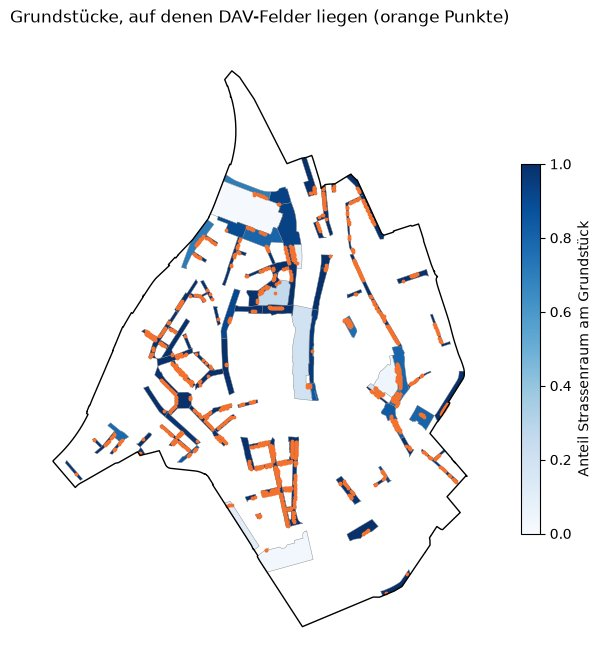

In [49]:
# Karte: Grundstücke mit DAV-Feldern, gefärbt nach dem Anteil Strassenraum; darüber die DAV-Punkte
karte = betroffen.merge(anteil, left_on="nummer", right_index=True)                       # Grundstücke mit ihren Anteilen
fig, ax = plt.subplots(figsize=(7.5, 8))
karte.plot(ax=ax, column="Strassenraum", cmap="Blues", vmin=0, vmax=1, edgecolor="grey", linewidth=0.3,
           legend=True, legend_kwds={"label": "Anteil Strassenraum am Grundstück", "shrink": 0.6})
punkte.plot(ax=ax, color="#f47230", markersize=3)                                         # DAV-Felder als orange Punkte
gebiet_tabelle.boundary.plot(ax=ax, color="black", lw=1)                                  # Umriss des Gebiets
ax.set_xlim(gebiet.bounds[0] - 100, gebiet.bounds[2] + 100)                               # Ausschnitt: Gebiet + 100 m
ax.set_ylim(gebiet.bounds[1] - 100, gebiet.bounds[3] + 100)
ax.set_axis_off()
ax.set_title("Grundstücke, auf denen DAV-Felder liegen (orange Punkte)")
fig.savefig(ABB / "01_grundstuecke_dav.png", dpi=130, bbox_inches="tight")
plt.show()

**Was die Karte zeigt.** Je dunkler ein Grundstück, desto grösser sein Anteil Strassenraum. Die meisten DAV-Felder (orange) liegen auf dunkelblauen, schmalen Grundstücken, die zusammen wie ein Strassennetz aussehen. Hell sind wenige grosse Grundstücke, die überwiegend aus anderem bestehen; sie stehen einzeln in der Tabelle darüber.

**Schritt 4: Hilft das Liegenschafteninventar der Stadt?** Die Datei `v_lvz_grundstueck` (Abschnitt 3) führt Grundstücke im Besitz der Stadt, mit der zuständigen Stelle (z. B. Grün Stadt Zürich). Wir zählen, wie viele DAV-Felder auf einem Grundstück liegen, das dort eingetragen ist. Verglichen wird über die Kennung des Grundstücks (EGRID), die in beiden Dateien steht.

In [50]:
inventar = gpd.read_file(ROH / "liegenschaften/v_lvz_grundstueck.geojson")                # Inventar der Stadt (ganze Stadt und Umland)
kennung = grundstuecke.set_index("nummer").egris_egrid                                    # Nachschlagetabelle: Nummer -> EGRID
im_inventar = auf.nummer.map(kennung).isin(inventar.egrid)                                # True, wenn das Grundstück im Inventar steht
print(f"Grundstücke im Inventar: {len(inventar)} | davon in unserer Grundstücksdatei: {int(inventar.egrid.isin(grundstuecke.egris_egrid).sum())}")
print(f"DAV-Felder auf einem Grundstück aus dem Inventar: {int(im_inventar.sum())} von {len(auf)}")

Grundstücke im Inventar: 5509 | davon in unserer Grundstücksdatei: 493
DAV-Felder auf einem Grundstück aus dem Inventar: 2 von 1252


**Was die Tabellen zeigen** (nur Beobachtungen):
- **Unter dem Punkt** liegt bei 1'023 der 1'252 Felder `Strasse` und bei 89 `Trottoir`, zusammen 89 %. Bei 122 Feldern (10 %) heisst die Bodenbedeckung `uebrige_befestigte.Parkplatz`, bei 5 `Hausumschwung`.
- **Grundstücke:** Die 1'252 Felder liegen auf 114 Grundstücken. 1'204 Felder (96 %) liegen auf Grundstücken, die mindestens zur Hälfte aus Strassenraum bestehen. Die übrigen 48 verteilen sich auf 8 Grundstücke; das grösste davon trägt 26 Felder, und unter diesen Feldern liegt die Bodenbedeckung `Parkplatz`.
- **Gebäude:** 1'242 Felder (99 %) liegen auf Grundstücken, die höchstens 5 % Gebäudefläche haben.
- **Inventar der Stadt:** Nur 2 der 1'252 Felder liegen auf einem dort eingetragenen Grundstück. Das Inventar führt Gebäude, Parks und Landreserven der Stadt, nicht die Strassen.
- **Was die Daten nicht sagen:** Wem ein Grundstück gehört und ob ein Parkfeld öffentlich zugänglich ist, steht in keiner dieser Dateien.

## 15. Was wir gesehen haben – und welche Fragen sich daraus für die Methodik ergeben

**Beobachtungen**
- Alle Rohdaten sind vorhanden und vollständig (Abschnitt 3).
- **Parkart:** Im Gebiet überwiegt `LPU` (Längsparkierung) deutlich vor `SCHPU` und `QPU` (Abschnitt 7).
- **Art:** Im Gebiet sind die markierten Felder fast alle `Standard`; Taxi, Güterumschlag, Polizei usw. machen einen grösseren Anteil aus als in der ganzen Stadt (Taxi-Plätze beim Hauptbahnhof). `Blaue Zone` kommt im Gebiet nur als Parkstreifen (Linien) vor.
- **Fehlende Werte:** `orientierung` und `art` sind vollständig; der Ort (`bezeichnung`) fehlt bei einem Teil der Felder.
- **Zeitpunkt:** Ein Teil der DAV-Felder trägt ein Datum der Inbetriebnahme nach der Befliegung 2024/25 (Abschnitt 7). Abschnitt 13 zeigt, wie sich diese Daten verteilen, und 20 solche Felder in allen drei Aufnahmen, mit der Beurteilung des Auftraggebers: 18 der 20 Felder sind schon im Bild von 2021 sichtbar.
- **Luftbild:** 4 Kanäle (Rot, Grün, Blau, Infrarot), 5 cm. In der Altstadt sind viele Flächen grau; Bäume verdecken im Sommer Teile der Strasse (Abschnitte 10 und 11).
- **Schwierige Stellen:** Bäume, Schatten, eine Baustelle und einzelne Felder machen Parkfelder schwer sichtbar (Abschnitt 12).
- **Unter Baumkronen:** Je nach Schwelle liegt im Sommerbild etwa jedes zehnte Parkfeld unter einer Krone; diese Felder bilden einige Dutzend Gruppen (Abschnitt 12, genaue Zahlen dort).
- **Grundstücke:** 96 % der DAV-Felder liegen auf Grundstücken, die mindestens zur Hälfte aus Strassenraum bestehen, 99 % auf Grundstücken mit höchstens 5 % Gebäudefläche. Unter 10 % der Punkte heisst die Bodenbedeckung `Parkplatz` statt Strasse oder Trottoir. Wem ein Grundstück gehört, steht in den offenen Daten nicht (Abschnitt 14).
- **Weitere Aufnahmen:** Frühjahr 2021 (laubfrei, 5 cm, aber älter) und Sommer 2026 (10 cm, jünger) zeigen dieselben Stellen anders (Abschnitt 11).

**Offene Fragen für die Methodik** (Antworten und Entscheide stehen im nächsten Notebook, `01b_methodik_leitfaden`)
1. Welche Felder zählen als Parkplatz – alle markierten, oder nur bestimmte Arten?
2. Welche Luftbilder werden verwendet – Sommer 2024/25, zusätzlich Frühjahr 2021, Sommer 2026 als echtes 10-cm-Bild?
3. Welche Kanäle – nur Farbe (Rot, Grün, Blau) oder auch Infrarot?
4. Wie gehen wir mit Feldern um, deren Datum nach der Befliegung liegt – und was bedeutet dieses Datum?
5. Wie gehen wir mit Feldern ohne Ortsangabe um, wo der Ort gebraucht wird?
6. Wie gehen wir mit verdeckten Feldern (Baum, Schatten) und mit Baustellen um?
7. Zählen gelbe Felder mit Kreuz und gelbe Linien ohne Unterteilung als Parkplatz?
8. Woran unterscheiden wir öffentlich zugängliche Parkfelder von Feldern auf privatem Grund (z. B. in Innenhöfen), die im Luftbild gleich aussehen?